# Part 1: Simulation Tools and Baseline

## Prepare Data
### Import all three datasets:
    Average Salary and Threshold
    Advertiser Sign-Ups
    Existing Agent Staffing
<b> Before building any tools, we will perform the following data cleanse:  
1. Eligible Ads:    
    - If Annual Budget > Threshold, then Eligible.    
2. Remove all Feb 29, 2025
>> </b>

In [1]:
#%pip install pandas openpyxl

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/aschan12/DADS5250Hackathon/main/DADS5250_Hackathon_Google_Data.xlsx"

# 2. Read directly into a DataFrame
df_salary_threshold = pd.read_excel(url, sheet_name="Agent Salary and Threshold", engine="openpyxl")
df_adv_sign_ups = pd.read_excel(url, sheet_name="Advertiser Sign-ups", engine="openpyxl")
df_exist_staff = pd.read_excel(url, sheet_name="Existing Agent Staffing", engine="openpyxl")

print(df_salary_threshold.head())
print(df_adv_sign_ups.head())
print(df_exist_staff.head())

   Country  Annual_Agent_Salary_USD  Advertiser_Eligibility_Threshold_USD
0      USA                    77721                                 35000
1       UK                    51650                                 27000
2  Germany                    51328                                 26000
3    India                    14118                                 13000
4   Brazil                    27950                                 29000
  Advertiser_ID Country         Sign_Up_Date  Projected_Annual_Budget
0       A000001     USA  2024-01-01 00:00:00                    84376
1       A000002     USA  2024-01-01 00:00:00                    57297
2       A000003     USA  2024-01-01 00:00:00                    34081
3       A000004     USA  2024-01-01 00:00:00                   154506
4       A000005     USA  2024-01-01 00:00:00                    23604
   Country  Existing_Agent_Count
0      USA                   652
1       UK                   589
2  Germany                   602
3   

In [3]:
# Left join the first two tables
eligible_ad = pd.merge(df_adv_sign_ups, df_salary_threshold, on='Country', how='left')
eligible_ad = eligible_ad.drop(columns=['Annual_Agent_Salary_USD'])

# Find eligible advertisers
eligible_ad['Eligible'] = (eligible_ad['Projected_Annual_Budget']> eligible_ad['Advertiser_Eligibility_Threshold_USD'])
eligible_ad = eligible_ad[eligible_ad['Eligible'] == True]

# Drop all on Feb 29, 2025 -> These are the ones that create Error when converting to_datetime
eligible_ad['Sign_Up_Date'] = pd.to_datetime(eligible_ad['Sign_Up_Date'], errors='coerce')
# 2. Drop all rows where 'Sign_Up_Date' became NaT
eligible_ad = eligible_ad.dropna(subset=['Sign_Up_Date'])

eligible_ad.head()

,Advertiser_ID,Country,Sign_Up_Date,Projected_Annual_Budget,Advertiser_Eligibility_Threshold_USD,Eligible
0,A000001,USA,2024-01-01,84376,35000,True
1,A000002,USA,2024-01-01,57297,35000,True
3,A000004,USA,2024-01-01,154506,35000,True
7,A000008,USA,2024-01-01,104967,35000,True
8,A000009,USA,2024-01-01,44165,35000,True


In [4]:
# Past Daily Demands
# daily_demand = eligible_ad.groupby(['Country', 'Sign_Up_Date']).size().reset_index(name='eligible_count')

#daily_demand.head()

In [5]:
# Monthly totals
#eligible_ad['Month'] = (eligible_ad['Sign_Up_Date'].dt.to_period('M'))
#monthly_demand = (eligible_ad.groupby(['Country', 'Month']).size())

#monthly_demand.head()

## Three Tools will be built:
### Tool 1. Simulator by country.
<b> This simulates advertiser assignment and agent capacity for a country on a day-by-day bases over a specified simulation period. It follows the following logic: </b>  
- When an eligible advertiser comes in, they sit in a waiting pool.
> - Path 1: If there's an agent available, they are assigned to it. Supported for 60 days, and 'graduate'.  
> - Path 2: No available agent, they will continue waiting. Everyday, if there's an agent available, they will be assigned. After 60 days if they are still unassigned, they are removed from the pool.

<b> Note: the following rules are observed: </b>
> 1. Each agent can support up to 10 advertisers.
> 2. Advertisers are assigned when agent capacity is available, in a first-in, first-out basis.
> 3. Assigned advertisers receive support for 60 days.
> 4. Capacity is released when an advertiser 'graduates'.
> 5. A staffing reduction in the next round cannot reduce the capacity below the number of advertisers already receiving support.

<b> This function simply simulates a scenario based on a staffing plan, it does not decide how many agents to hire or terminate. </b>

In [6]:
def simulate_country(advertisers, country, staffing_plan, start_date="2024-01-01", end_date="2024-12-31"):
    '''
       Inputs:
             advertisers (df): dataframe containing a list of advertisers by country and sign-up dates.
                               Required columns:
                                   Advertiser_ID, Contry, and Sign-Up Dates
                country (str): country to simulate
           staffing_plan (df): dataframe containing staffing plan (agent count) of a country by month
                               Required columns:
                                   Country, Month, Agents
            start_date (date): start date of simulation period
              end_date (date): end date of simulation period

        Output: Two dataframes
            1. advertiser_result:
                One row per advertiser, containing:
                    - advertiser_ID
                    - status: Not arrived (not yet signed-up), Waiting, Assigned, Graduated, Expired
                    - assignment_date, graduation_date, expiration_date
            2. daily_result:
                One row per simulation day, containing:
                    - date, Country, agents, capacity (agent*10)
                    - new_eligible, assigned_today, expired_today, supported, waiting (all counts)
                    - utilization
    '''

    df = advertisers[advertisers['Country'] == country].copy()

    df['status'] = 'NOT_ARRIVED'
    df['assignment_date'] = pd.NaT
    df['graduation_date'] = pd.NaT
    df['expiration_date'] = pd.NaT

    daily_results = []

    dates = pd.date_range(start=start_date, end=end_date, freq="D")

    for current_date in dates:

        # Enhancement 1a: dynamic staffing
        current_month = current_date.to_period("M")
        staffing_row = staffing_plan[(staffing_plan["Country"] == country) & (staffing_plan["Month"] == current_month)]
        if staffing_row.empty:
            raise ValueError(f"No staffing data found for "
                             f"{country}, {current_month}")
        agent_count = int(staffing_row["Agents"].iloc[0])

        # 1. Graduate advertisers
        graduating = ((df["status"] == "ASSIGNED")  & (df["graduation_date"] <= current_date))
        graduated_today = graduating.sum()
        df.loc[graduating, "status"] = "GRADUATED"

        # 2. Add today's advertisers
        arrivals = ((df["Sign_Up_Date"] == current_date) & (df["status"] == "NOT_ARRIVED") )
        new_eligible_today = arrivals.sum()
        df.loc[arrivals, "status"] = "WAITING"

        # 3. Expire old waiting advertisers
        expired = ((df["status"] == "WAITING") & (current_date > df["Sign_Up_Date"]+ pd.Timedelta(days=60)))
        expired_today = expired.sum()
        df.loc[expired, "status"] = "EXPIRED"
        df.loc[expired, "expiration_date"] = current_date

        # 4. Calculate capacity
        total_capacity = agent_count * 10
        currently_supported = (df["status"] == "ASSIGNED").sum()
        available_capacity = max(0, total_capacity - currently_supported)

        # Enhancement 1b: raise error if staff reduction causes currently supported advertisers to suddenly go without an agent
        if currently_supported > total_capacity:
            raise ValueError(f"Infeasible staffing plan: "
                             f"{country} on {current_date.date()} " f"has {currently_supported} supported advertisers "
                            f"but only {total_capacity} available capacity.")

        # 5. First-In First-Out assignment
        waiting = (df[df["status"] == "WAITING"].sort_values(["Sign_Up_Date", "Advertiser_ID"]))
        to_assign = waiting.head(available_capacity)
        assigned_today = len(to_assign)
        if assigned_today > 0:
            df.loc[to_assign.index,"status"] = "ASSIGNED"
            df.loc[to_assign.index, "assignment_date"] = current_date
            df.loc[to_assign.index, "graduation_date"] = (current_date + pd.Timedelta(days=60)            )

        # 6. Daily results
        supported = (df["status"] == "ASSIGNED").sum()
        waiting_count = (df["status"] == "WAITING").sum()
        utilization = (supported / total_capacity if total_capacity > 0 else 0)
        daily_results.append({
            "date": current_date,
            "Country": country,
            "agents": agent_count,
            "capacity": total_capacity,
            "new_eligible": new_eligible_today,
            "assigned_today": assigned_today,
            "graduated_today": graduated_today,
            "expired_today": expired_today,
            "supported": supported,
            "waiting": waiting_count,
            "utilization": utilization
        })

    return (df, pd.DataFrame(daily_results))

### Tool 2. Staffing schedule
<b> This converts monthly hiring and termination decisions into the actual productive agent headcount available each month, which calculating total staffing and termination costs. </b>  
<b> Note: the following rules are observed: </b>
> 1. Hiring and termination decisions takes effect after one month.
    - Agents hired in month M will become productive only in month M+1.  
    - Agents to be terminated in month M will leave in month M+1.
> 2. Every month, each agent is paid annual_salary / 12.
> 3. Termination incurs a one-time cost of 0.40 * annual_salary.

<b> This function simply simulates the staffing plan as input for Tool 1. </b>

In [7]:
def build_staffing_schedule(initial_agents, decisions):
    '''
        Inputs:
            - initial_agents (integer): obtained from df_exist_staff
            - decisions (df): Monthly Staffing Decisions
                - Required Columns:
                    - Country
                    - Month ('2026-01')
                    - Hires
                    - Terminations

        Outputs:
            - staffing plan: a dataframe where each row contains:
                - Country
                - Month
                - Agents: available to support advertisers
                - agents_ramping: agents ramping up and not available for support
                - termination_notices: notices issued that month for the country
                - annual_agent_salary_USD, monthly_salary
                - paid_agents, salary_cost, termination_cost, total_cost
    '''

    decisions = decisions.sort_values("Month").copy()
    active_agents = initial_agents

    previous_hires = 0
    previous_terminations = 0

    results = []

    for _, row in decisions.iterrows():

        # Decisions from previous month
        # take effect this month
        active_agents += previous_hires
        active_agents -= previous_terminations

        if active_agents < 0:
            raise ValueError(f"Active agents became negative " f"in {row['Month']}")

        results.append({
            "Country": row["Country"],
            "Month": row["Month"],
            "Agents": active_agents,
            "Agents_Ramping": int(row["Hires"]),
            "Hires": int(row["Hires"]),
            "Terminations_Notices": int(
                row["Terminations"]
            )
        })

        previous_hires = int(row["Hires"])
        previous_terminations = int(row["Terminations"])

    staffing_plan = pd.DataFrame(results)
    staffing_plan = staffing_plan.merge(df_salary_threshold[["Country", "Annual_Agent_Salary_USD"]],
                                        on="Country", how="left")
    staffing_plan['Monthly_Salary'] = staffing_plan['Annual_Agent_Salary_USD']/12
    staffing_plan["Paid_Agents"] = (staffing_plan["Agents"] + staffing_plan["Agents_Ramping"])
    staffing_plan["Salary_Cost"] = (staffing_plan["Paid_Agents"] * staffing_plan["Monthly_Salary"])
    staffing_plan["Termination_Cost"] = (staffing_plan["Terminations_Notices"] * staffing_plan["Annual_Agent_Salary_USD"]* 0.40)
    staffing_plan["Total_Cost"] = (staffing_plan["Salary_Cost"] + staffing_plan["Termination_Cost"])

    return staffing_plan

### Tool 3. Evaluate staffling plan
<b> This evaluates the performance of a complete staffing simulation, combining advertiser service outcomes, agent utilization, staffing costs, and expected revenue uplift. </b>  
<b> Note: the following metrics are measured: </b>
> 1. Timely Advertiser Support:
     -  Number of advertisers that received support/expired
     -  Advertiser expiration rate
     -  Average, 90th percentile, and maximum waiting time for agent support
> 2. Cost
     - Total staffing costs across the whole evaluation period
> 3. Revenue Impact
     - Expected uplift E[X] to be calculated:
        - Potential uplift = if every eligible advertiser received support
        - Expected uplift = actual advertisers that received support
> 4. Net financial impact = Revenue - Cost


In [8]:
revenue_uplift = {0.00: 0.05, 0.05: 0.15, 0.10: 0.25, 0.15: 0.25, 0.20: 0.20, 0.25: 0.10}
expected_uplift = sum(uplift * probability for uplift, probability in revenue_uplift.items())

print(expected_uplift)

0.135


In [9]:
def evaluate_plan(advertiser_results, daily_results, staffing_plan):
    '''
        Inputs:
            - advertiser_results: advertiser results from function simulate_country()
            - daily_results: daily results from function simulate_country()
            - staffing_plan: monthly_staffing plan created from function build_staffing_schedule()

        Output:
            - Dictionary containing the following metrics:
                - advertisers supported, advertisers expired, expiration rate, average wait days, percentile 90 waiting days
                - average agent utilization, total staffing cost
                - expected uplift rate, potential revenue uplift, expected revenue uplift
                - net finances: revenue - cost

    '''

    completed = advertiser_results[advertiser_results["assignment_date"].notna()].copy()
    completed["wait_days"] = (completed["assignment_date"] - completed["Sign_Up_Date"]).dt.days
    max_wait = completed["wait_days"].max()
    avg_wait = completed["wait_days"].mean()
    p90_wait = completed["wait_days"].quantile(0.90)
    expired = (advertiser_results["status"] == "EXPIRED").sum()
    expiration_rate = (expired / len(advertiser_results))
    avg_utilization = (daily_results["utilization"].mean())
    peak_utilization = (daily_results["utilization"].max())
    total_staffing_cost = staffing_plan["Total_Cost"].sum()

    expected_uplift_rate = 0.1375
    supported = advertiser_results[advertiser_results["assignment_date"].notna()].copy()
    total_potential_revenue_uplift = (advertiser_results["Projected_Annual_Budget"].sum() * expected_uplift_rate)
    expected_revenue_uplift = (supported["Projected_Annual_Budget"].sum() * expected_uplift_rate)
    net_financial_impact = (expected_revenue_uplift - total_staffing_cost)


    return {
        "advertisers_supported": len(completed),
        "advertisers_expired": int(expired),
        "average_wait_days": avg_wait,
        "p90_wait_days": p90_wait,
        "average_utilization": avg_utilization,
        "expired_advertisers": expired,
        "expiration_rate": expiration_rate,
        "total_staffing_cost": total_staffing_cost,
        "expected_uplift_rate": expected_uplift_rate,
        "potential_revenue_uplift": float(total_potential_revenue_uplift),
        "expected_revenue_uplift": float(expected_revenue_uplift),
        # Overall financial result
        "net_financial_impact":float(net_financial_impact)
    }

### With three functions ready, we can start building for 2026. For this Hackathon, we need to use AI to help with staffing, to understand this, we will compare its results against a baseline.

<b> In the next section, we will build this baseline. To do this: </b>
1. Forecast 2026 demand based on 2024-2025 data.
   - Note that we are making two forecasts: first is the monthly forecast, second is the actual advertiser-level forecast.
2. Using the forecasted information, feed through the three functions.
   -  The baseline scenario will be: 0 hired and 0 termination - use existing agent count.

<b> This baseline result will be used to compare against AI's results. </b>

### Step 1: Find 2026 forecast: both monthly-level and advertiser-level.

In [10]:
# Prepare data for forecast

import numpy as np
import pandas as pd

# Monthly totals
eligible_ad['Month'] = (eligible_ad['Sign_Up_Date'].dt.to_period('M'))
monthly_demand = (eligible_ad.groupby(['Country', 'Month']).size().reset_index(name="Eligible_Advertisers"))
monthly_demand["Year"] = (monthly_demand["Month"].dt.year)
monthly_demand["Month_Number"] = (monthly_demand["Month"].dt.month)

demand_history = (monthly_demand.pivot_table(index=["Country", "Month_Number"],
        columns="Year",
        values="Eligible_Advertisers",
        aggfunc="sum",
        fill_value=0).reset_index())
demand_history = demand_history.rename(columns={2024: "Demand_2024", 2025: "Demand_2025"})

demand_history["Growth_Rate"] = ((demand_history["Demand_2025"] - demand_history["Demand_2024"])/ demand_history["Demand_2024"])
demand_history.head()


Year,Country,Month_Number,Demand_2024,Demand_2025,Growth_Rate
0,Argentina,1,53,90,0.698113
1,Argentina,2,66,70,0.060606
2,Argentina,3,69,59,-0.144928
3,Argentina,4,71,79,0.112676
4,Argentina,5,67,65,-0.029851


<b> Build the first forecast function: this forecasts the monthly eligible advertisers based on 2024-2025 values. </b>

In [11]:
import pandas as pd
import numpy as np

def forecast_2026_monthly_demand(monthly_demand, min_growth=-0.20, max_growth=0.30):
    """
        Forecasts monthly eligible advertiser demand for 2026 using 2024 and 2025 monthly demand.

        Forecast logic:
            Growth = (2025 Demand - 2024 Demand) / 2024 Demand
            2026 Forecast = 2025 Demand * (1 + Applied Growth)

        Growth is capped to prevent extreme forecasts:
            min_growth : Minimum allowed growth rate.
                Default = -20%.
            max_growth : Maximum allowed growth rate.
                Default = +30%.

    """

    # Cap extreme growth
    monthly_demand["Applied_Growth"] = (monthly_demand["Growth_Rate"].clip(lower=min_growth, upper=max_growth))

    # Forecast 2026
    monthly_demand["Forecast_2026"] = (monthly_demand["Demand_2025"] * (1 + monthly_demand["Applied_Growth"])).round().astype(int)

    # Create 2026 Month
    monthly_demand["Month"] = pd.PeriodIndex([f"2026-{month:02d}"for month in monthly_demand["Month_Number"]],freq="M")

    # Final output
    forecast = monthly_demand[
        ["Country",
            "Month",
            "Month_Number",
            "Demand_2024",
            "Demand_2025",
            "Growth_Rate",
            "Applied_Growth",
            "Forecast_2026"]].copy()


    return (forecast.sort_values(["Country", "Month"]).reset_index(drop=True))

In [12]:
forecast_2026 = forecast_2026_monthly_demand(demand_history)
forecast_2026.head()

Year,Country,Month,Month_Number,Demand_2024,Demand_2025,Growth_Rate,Applied_Growth,Forecast_2026
0,Argentina,2026-01,1,53,90,0.698113,0.300000,117
1,Argentina,2026-02,2,66,70,0.060606,0.060606,74
2,Argentina,2026-03,3,69,59,-0.144928,-0.144928,50
3,Argentina,2026-04,4,71,79,0.112676,0.112676,88
4,Argentina,2026-05,5,67,65,-0.029851,-0.029851,63


<b> Build the second forecast function: this forecasts eligible advertisers information based on 2026 monthly forecasts, and 2024-2025 values. </b>

In [13]:
def create_2026_forecast_advertisers(forecast_2026, historical_advertisers, random_seed=42):
    """
    Converts monthly 2026 demand forecasts into advertiser-level records for the daily staffing simulator.

    historical_advertisers : from 2024-2025
    random_seed : Makes the generated forecast reproducible.

    """

    forecast = forecast_2026.copy()
    historical = historical_advertisers.copy()

    # Ensure dates have the correct type
    historical["Sign_Up_Date"] = pd.to_datetime(historical["Sign_Up_Date"])

    # Ensure only 2024 and 2025 years
    historical = historical[historical["Sign_Up_Date"].dt.year.isin([2024, 2025])].copy()
    historical["Month_Number"] = (historical["Sign_Up_Date"].dt.month)
    historical["Day_Of_Month"] = (historical["Sign_Up_Date"].dt.day)

    rng = np.random.default_rng(random_seed)

    generated_rows = []
    advertiser_number = 1

    # Generate advertisers for each Country + Month
    for _, row in forecast.iterrows():

        country = row["Country"]
        month_number = int(row["Month_Number"])

        forecast_count = int(row["Forecast_2026"])

        # Historical advertisers from the same country and calendar month
        historical_pool = historical[(historical["Country"] == country) & (historical["Month_Number"] == month_number)]

        # Sample historical advertisers
        sampled = historical_pool.sample(n=forecast_count, replace=True, random_state=(random_seed + advertiser_number))
        sampled = sampled.reset_index(drop=True)

        # Create corresponding 2026 records
        for _, hist_row in sampled.iterrows():

            signup_date = pd.Timestamp(year=2026, month=month_number, day=int(hist_row["Day_Of_Month"]))

            generated_rows.append({
                "Advertiser_ID": f"F2026_{advertiser_number:08d}",
                "Country": country,
                "Sign_Up_Date": signup_date,
                "Projected_Annual_Budget": hist_row["Projected_Annual_Budget"],
                "Data_Type":"2026_FORECAST"})

            advertiser_number += 1

    forecast_advertisers = pd.DataFrame(generated_rows)

    return (forecast_advertisers.sort_values(["Country", "Sign_Up_Date"]).reset_index(drop=True))

In [14]:
ad_forecast_2026 = create_2026_forecast_advertisers(forecast_2026, historical_advertisers=eligible_ad)
ad_forecast_2026.head()

,Advertiser_ID,Country,Sign_Up_Date,Projected_Annual_Budget,Data_Type
0,F2026_00000036,Argentina,2026-01-02,7026,2026_FORECAST
1,F2026_00000072,Argentina,2026-01-02,8930,2026_FORECAST
2,F2026_00000077,Argentina,2026-01-02,28609,2026_FORECAST
3,F2026_00000103,Argentina,2026-01-02,8930,2026_FORECAST
4,F2026_00000005,Argentina,2026-01-03,9422,2026_FORECAST


### Step 2: Calculate Baseline For All Countries in 2026

In [15]:
all_staffing_plans = []
all_advertiser_results = []
all_daily_results = []
all_baseline_summary = []

for _, row in df_exist_staff.iterrows():

    country = row["Country"]
    agents = int(row["Existing_Agent_Count"])
    baseline_decisions = pd.DataFrame({
        "Country": [country] * 12,
        "Month": pd.period_range(
            "2026-01",
            "2026-12",
            freq="M"),
        "Hires": [0] * 12,
        "Terminations": [0] * 12
    })

    baseline_staffing_plan = build_staffing_schedule(initial_agents=agents, decisions=baseline_decisions)
    advertiser_result, daily_result = simulate_country(ad_forecast_2026, country=country, staffing_plan=baseline_staffing_plan, start_date="2026-01-01", end_date="2026-12-31")

    all_staffing_plans.append(baseline_staffing_plan)
    all_advertiser_results.append(advertiser_result)
    all_daily_results.append(daily_result)

    #evaluate_plan(advertiser_results= advertiser_result,daily_results = daily_result, staffing_plan = baseline_staffing_plan)


simulation_daily = pd.concat(all_daily_results, ignore_index=True)
simulation_advertisers = pd.concat(all_advertiser_results,ignore_index=True)
simulation_staffing = pd.concat(all_staffing_plans, ignore_index=True)

In [16]:
#baseline_staffing_plan.head()
#simulation_daily.head()
#simulation_advertisers.head()
simulation_staffing.head()

,Country,Month,Agents,Agents_Ramping,Hires,Terminations_Notices,Annual_Agent_Salary_USD,Monthly_Salary,Paid_Agents,Salary_Cost,Termination_Cost,Total_Cost
0,USA,2026-01,652,0,0,0,77721,6476.75,652,4222841.0,0.0,4222841.0
1,USA,2026-02,652,0,0,0,77721,6476.75,652,4222841.0,0.0,4222841.0
2,USA,2026-03,652,0,0,0,77721,6476.75,652,4222841.0,0.0,4222841.0
3,USA,2026-04,652,0,0,0,77721,6476.75,652,4222841.0,0.0,4222841.0
4,USA,2026-05,652,0,0,0,77721,6476.75,652,4222841.0,0.0,4222841.0


<b> Since all results are concatenated, the following function wraps it so it's easy to query individual country results. </b>

In [17]:
def evaluate_country(country, simulation_advertisers, simulation_daily, simulation_staffing):

    advertiser_results = simulation_advertisers[simulation_advertisers["Country"] == country]
    daily_results = simulation_daily[simulation_daily["Country"] == country]
    staffing_plan = simulation_staffing[simulation_staffing["Country"] == country]
    metrics = evaluate_plan(advertiser_results=advertiser_results,daily_results=daily_results,staffing_plan=staffing_plan)
    metrics["Country"] = country

    return metrics

In [18]:
usa_metrics = evaluate_country("USA", simulation_advertisers, simulation_daily, simulation_staffing)

usa_metrics

{'advertisers_supported': 13046,
 'advertisers_expired': 0,
 'average_wait_days': np.float64(0.0),
 'p90_wait_days': np.float64(0.0),
 'average_utilization': np.float64(0.2976132448104883),
 'expired_advertisers': np.int64(0),
 'expiration_rate': np.float64(0.0),
 'total_staffing_cost': np.float64(50674092.0),
 'expected_uplift_rate': 0.1375,
 'potential_revenue_uplift': 154084310.875,
 'expected_revenue_uplift': 154084310.875,
 'net_financial_impact': 103410218.875,
 'Country': 'USA'}

<div style="font-family: 'Segoe UI', sans-serif; background-color: #f4faff; padding: 20px; border-radius: 12px; border-left: 6px solid #3399ff; color: #1a1a1a">

  <h1 style="color: #0066cc;"><strong>Part 2: AI Staffing Planner (LangGraph)</strong></h1>
  <p><strong style="color: #3399ff;">An LLM plans the staffing, the simulator checks it, a manager approves it</strong></p>

  <h2 style="color: #004c99;">Overview</h2>
  <p>
    Part 1 built three tools: <strong>Tool 1</strong> simulates advertisers day by day,
    <strong>Tool 2</strong> turns hire/terminate decisions into a costed schedule, and <strong>Tool 3</strong>
    scores a plan. In Part 2 an <strong>LLM decides the monthly headcount</strong> for each country. In each
    attempt it first writes an analysis, then proposes three candidate plans (target productive agents per month).
    Python converts each candidate into hires and termination notices, validates it and simulates it.
  </p>
  <p>
    If no candidate passes, the graph tells the LLM what went wrong, month by month and in dollars, and asks it to
    revise. Once a plan passes, the LLM gets up to two more rounds to improve on the best plan so far. If nothing
    passes, the graph falls back to a rule-based <strong>heuristic</strong> plan, so every country ends with a
    valid plan. The LLM then writes an approval memo, and a manager can approve it or push back in plain English.
  </p>

  <h3 style="color: #0059b3;">Objectives</h3>
  <ul>
    <li>Use an LLM to recommend 2026 headcount per country</li>
    <li>Validate and score every AI candidate with Tools 1–3, then revise and refine automatically</li>
    <li>Compare three plans: <strong>baseline</strong> (no changes), <strong>heuristic</strong> (rule-based) and <strong>AI</strong></li>
    <li>Pause for human approval and turn manager feedback into hard constraints</li>
  </ul>

  <h3 style="color: #0059b3;">Where the LLM is used</h3>
  <ul>
    <li><code>plan_staffing</code>: analysis plus three candidate headcount plans (structured output, larger planning model)</li>
    <li><code>write_memo</code>: explains the plan to the approver (structured output, mini model)</li>
    <li><code>parse_feedback</code>: turns the manager's reply into constraints (structured , mini model)</li>
  </ul>
  <p>
    The heuristic is used only as the fallback and as a benchmark. The LLM never sees the heuristic or its plan.
    Every number (costs, waiting, expirations, revenue) comes from the tools, not the LLM.
  </p>
</div>

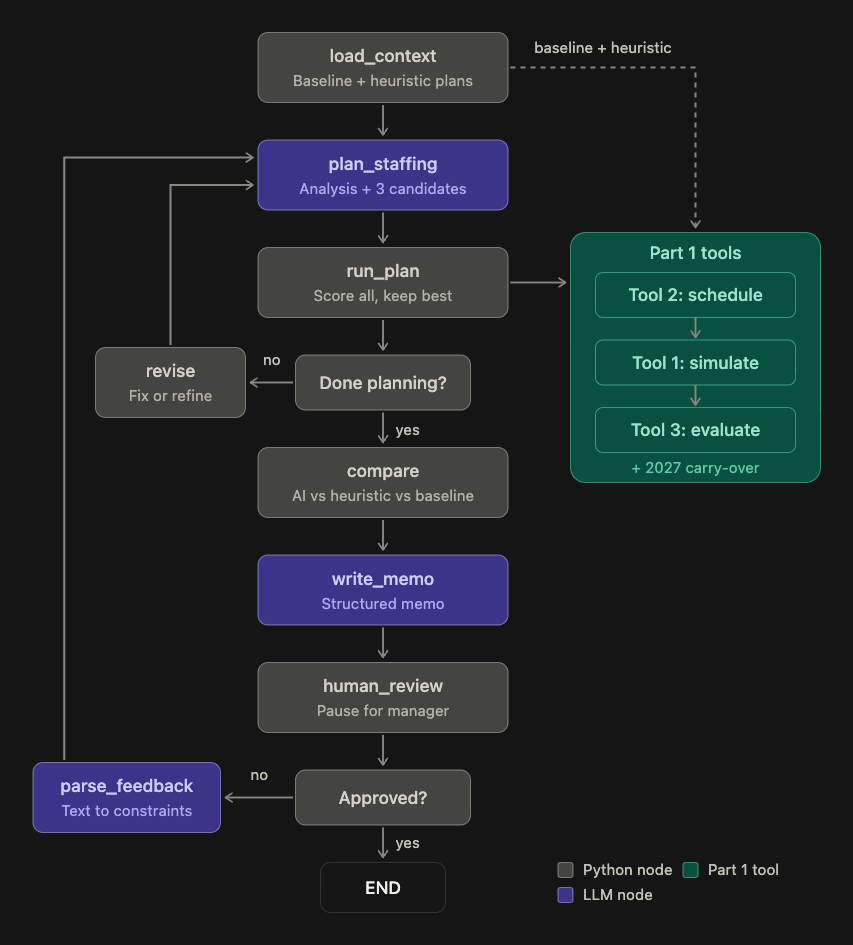

## Graph Steps

- **`load_context` (Python):** Loads the country's 2026 forecast, salary and starting headcount. It simulates two reference plans with the Part 1 tools: the **baseline** (keep current staffing) and the **heuristic** (a rule-based plan used only as fallback and benchmark). It also records how many agents are actually busy each month in the baseline.

- **`plan_staffing` (LLM, larger model):** Writes an analysis first (busy months, idle capacity, which notice months pay off), then proposes **3 candidate plans** with different strategies. Each candidate gives target productive agents for February to December, with a reason per month. It sees the forecast, the busy agents, the costs and rules, and any manager constraints, but never the heuristic.

- **`run_plan` (Python):** Converts each candidate's headcounts into hires and termination notices, checks the manager's constraints, and runs it through Tool 2, Tool 1 and Tool 3, with the 2027 carry-over added to the score. A candidate passes if:
  - it is feasible;
  - no more than 1% of advertisers expire;
  - it beats the baseline;
  - it is not a do-nothing plan when savings are available.

  The best passing plan across all attempts is kept.

- **Done planning? (decision):** **Yes** if the 5-attempt limit is reached, the latest round did not improve on the best plan, or the 2 refine rounds after the first pass are used up. Otherwise **no**.

- **`revise` (Python):** Writes feedback for the next attempt.
  - **Fix mode** (nothing has passed yet): what went wrong with each candidate, a month-by-month table of agents, busy agents, idle agents, idle cost, waiting and expirations, and a dollar breakdown against the baseline.
  - **Refine mode** (something has passed): the same table for the best plan so far, with a request to cut the remaining idle cost.

- **`compare` (Python):** Picks the final plan: the best AI plan, or the heuristic if no AI plan passed (or the baseline if the heuristic does not beat it). It lines up all three plans side by side.

- **`write_memo` (LLM, mini):** Writes a structured approval memo: headline, why this plan, AI vs. heuristic, risks and assumptions. It uses only the numbers Python provides.

- **`human_review` (pause):** The graph stops and shows the memo to the manager.

- **Approved? (decision):** **Yes** ends the run. **No** sends the manager's written reply to `parse_feedback`.

- **`parse_feedback` (LLM, mini):** Turns the reply into hard constraints, such as a minimum headcount, no notices before a given month, or a cap on notices per month. Months are forced to 2026. It rebuilds the heuristic under the same rules so the comparison stays fair, then sends the run back to `plan_staffing`.

## 0. Setup

In [19]:
%%capture --no-stderr
# Install LangGraph + LangChain OpenAI integration
!pip install --quiet -U langgraph langchain_core langchain_openai

In [20]:
# === API key: Colab secret if available, otherwise prompt ===
import os
from getpass import getpass

if not os.environ.get("OPENAI_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    except Exception:
        os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")

MODEL_NAME = "gpt-4.1-mini"   # memo and feedback parsing (mini)
PLANNER_MODEL = "gpt-4.1"     # staffing plans (larger model); set to a model available on your account
print("API key loaded | planner:", PLANNER_MODEL, "| other LLM nodes:", MODEL_NAME)

API key loaded | planner: gpt-4.1 | other LLM nodes: gpt-4.1-mini


In [21]:
# ==========================================================
# 1. Constants, constraints and State
# ----------------------------------------------------------
# Defines:
#   - case constants and planning settings
#   - PlanConstraints : hard rules set by the manager
#   - StaffingState   : shared memory for one country's run
# ==========================================================
import math
import re
import numpy as np
import pandas as pd
from typing import Literal, Optional
from typing_extensions import TypedDict
from pydantic import BaseModel, Field

# Case constants
EXPECTED_UPLIFT = 0.135        # sum(uplift x probability) from the revenue table
SUPPORT_DAYS = 60              # each advertiser is supported for 60 days
CAPACITY_PER_AGENT = 10        # max advertisers per agent at any time
TERMINATION_COST_RATE = 0.40   # firing cost as a share of annual salary
MONTHS_2026 = [str(m) for m in pd.period_range("2026-01", "2026-12", freq="M")]

# Planning settings
CANDIDATES_PER_ATTEMPT = 3     # candidate plans the LLM proposes per attempt
MAX_ATTEMPTS = 5               # total planning attempts per run
REFINE_ROUNDS = 2              # extra attempts after the first passing plan
MIN_IMPROVEMENT_SHARE = 0.001  # a refinement must improve net by >= 0.1% of baseline staffing cost
MAX_EXPIRATION_RATE = 0.01     # a plan passes only if <= 1% of advertisers expire
CARRYOVER_MONTHS = 3           # months of 2027 salary at December headcount added to every plan's cost
USE_FAST_SIMULATOR = True      # queue-based Tool 1 (same results, much faster); False uses Part 1's version

# Planner input: agents busy each month in the BASELINE SIMULATION (peak advertisers supported / 10).
# This is simulator output, not the heuristic. Set to False to give the LLM sign-up counts only.
SHOW_BASELINE_USAGE = True

# Heuristic (fallback and benchmark only; never shown to the LLM)
HEURISTIC_BUFFER = 0.10        # extra capacity on top of expected load
HOLD_MONTHS = 6                # keep surplus agents needed again within 6 months


# Manager constraints (all optional)
class PlanConstraints(BaseModel):
    """Hard rules the plan must respect. Leave a field null if the manager didn't mention it."""
    min_agents: Optional[int] = Field(None, description="Productive agents must never drop below this")
    max_agents: Optional[int] = Field(None, description="Productive agents must never exceed this")
    no_terminations_before: Optional[str] = Field(
        None, description="No termination notices before this month of 2026, format 2026-MM")
    max_terminations_per_month: Optional[int] = Field(
        None, description="Cap on termination notices in any single month")
    notes: Optional[str] = Field(
        None, description="Any other preference, in a short sentence, for the planner to consider")


# State schema
class StaffingState(TypedDict, total=False):
    country: str
    context: dict              # forecast, salary, start agents, economics, baseline usage
    constraints: dict          # PlanConstraints as a dict
    baseline: dict             # scored plan: levels, decisions, metrics, costs, monthly detail
    heuristic: dict            # scored plan (fallback and benchmark)
    ai_plan: dict              # latest LLM output: analysis + raw candidates
    ai_result: dict            # latest attempt's chosen candidate, scored
    candidate_results: list    # latest attempt: one summary per candidate
    best: Optional[dict]       # best passing AI candidate so far
    first_pass_attempt: Optional[int]
    improved: bool             # did the latest attempt improve on the best plan?
    passed: bool               # is there a passing AI plan?
    attempts: int              # LLM planning attempts so far
    attempt_log: list          # one row per candidate per attempt
    revise_notes: Optional[str]  # feedback for the next planning attempt
    comparison: dict           # three-way comparison + final plan choice
    memo: dict                 # numbers + LLM narrative
    feedback: Optional[str]    # manager's reply if not approved
    approved: bool

## 2. Helpers

Shared functions used by the nodes.

**Faster simulator.** `simulate_country_fast()` applies exactly the same rules as Tool 1 (graduate, arrive,
expire, capacity check, first-in first-out assignment) but keeps waiting advertisers in a queue instead of
re-scanning every advertiser each day. It is about 40 times faster, which makes three candidates per attempt and
the refine rounds way more affordable. The cell after the helpers checks that it reproduces Tool 1 exactly.

**`run_tools()`** chains Tool 2, the simulator and Tool 3. It returns simulator errors as data, the salary and
termination cost split, the carry-over-adjusted net, and month-level detail (peak supported, peak waiting,
expirations) used for feedback.

**Heuristic plan (fallback and benchmark).** Three rules, applied per country:

1. **Required agents.** Each advertiser is supported for about two months, so the load in month *m* is roughly
   this month's plus last month's eligible sign-ups (or the previous two months' at the start of the month,
   whichever is larger), plus a 10% buffer, divided by 10.
2. **Hire one month early** to cover ramp-up. January cannot change.
3. **Hold rule.** Firing costs 40% of annual salary (4.8 months of pay) plus a ramp-up month if the agent is
   replaced later, so agents needed again within 6 months are kept.

**The heuristic is never shown to the LLM.**

State values are stored as plain lists and dicts (not DataFrames) because the checkpointer that supports
pausing for human review can only save simple Python types.

In [22]:
# ==========================================================
# 2. Deterministic helpers (no LLM)
# ----------------------------------------------------------
# Defines:
#   - simulate_country_fast() : queue-based Tool 1 with identical results
#   - levels_to_decisions()   : headcount path -> Hires/Terminations records
#   - run_tools()             : Tool 2 -> simulator -> Tool 3, errors returned as data
#   - notice_value()          : value of cutting one agent, by notice month (with carry-over)
#   - required_agents(), heuristic_levels(), build_heuristic() : heuristic plan
# ==========================================================
from collections import deque, defaultdict

def simulate_country_fast(advertisers, country, staffing_plan, start_date="2024-01-01", end_date="2024-12-31"):
    """Same rules and outputs as simulate_country (Tool 1), using a queue instead of
    re-scanning every advertiser each day. Results match Tool 1 exactly (see check below)."""
    df = advertisers[advertisers["Country"] == country].copy()
    df = df.sort_values(["Sign_Up_Date", "Advertiser_ID"])
    n = len(df)
    signup = df["Sign_Up_Date"].to_numpy()
    idx = df.index.to_numpy()

    dates = pd.date_range(start=start_date, end=end_date, freq="D")
    in_window = (df["Sign_Up_Date"] >= dates[0]) & (df["Sign_Up_Date"] <= dates[-1])
    arrivals_by_day = defaultdict(list)
    for pos in np.flatnonzero(in_window.to_numpy()):
        arrivals_by_day[signup[pos]].append(pos)          # already in (date, ID) order

    plan = staffing_plan[staffing_plan["Country"] == country]
    agents_by_month = dict(zip(plan["Month"], plan["Agents"]))

    status = np.array(["NOT_ARRIVED"] * n, dtype=object)
    assign_date = [pd.NaT] * n
    grad_date = [pd.NaT] * n
    exp_date = [pd.NaT] * n

    queue = deque()                      # waiting advertisers, oldest first
    graduating_on = defaultdict(int)     # date -> number of advertisers graduating
    grad_positions = defaultdict(list)
    supported = 0
    daily_results = []
    sixty = pd.Timedelta(days=60)

    for current_date in dates:
        current_month = current_date.to_period("M")
        if current_month not in agents_by_month:
            raise ValueError(f"No staffing data found for {country}, {current_month}")
        agent_count = int(agents_by_month[current_month])

        # 1. Graduate advertisers
        graduated_today = graduating_on.pop(current_date, 0)
        for pos in grad_positions.pop(current_date, []):
            status[pos] = "GRADUATED"
        supported -= graduated_today

        # 2. Add today's advertisers
        todays = arrivals_by_day.get(current_date.to_datetime64(), [])
        for pos in todays:
            status[pos] = "WAITING"
            queue.append(pos)
        new_eligible_today = len(todays)

        # 3. Expire old waiting advertisers (the queue is oldest-first)
        expired_today = 0
        while queue and current_date > pd.Timestamp(signup[queue[0]]) + sixty:
            pos = queue.popleft()
            status[pos] = "EXPIRED"
            exp_date[pos] = current_date
            expired_today += 1

        # 4. Capacity
        total_capacity = agent_count * 10
        if supported > total_capacity:
            raise ValueError(f"Infeasible staffing plan: {country} on {current_date.date()} "
                             f"has {supported} supported advertisers but only {total_capacity} available capacity.")
        available_capacity = max(0, total_capacity - supported)

        # 5. First-in first-out assignment
        assigned_today = min(available_capacity, len(queue))
        if assigned_today:
            g = current_date + sixty
            for _ in range(assigned_today):
                pos = queue.popleft()
                status[pos] = "ASSIGNED"
                assign_date[pos] = current_date
                grad_date[pos] = g
                grad_positions[g].append(pos)
            graduating_on[g] += assigned_today
            supported += assigned_today

        # 6. Daily results
        daily_results.append({
            "date": current_date, "Country": country, "agents": agent_count,
            "capacity": total_capacity, "new_eligible": new_eligible_today,
            "assigned_today": assigned_today, "graduated_today": graduated_today,
            "expired_today": expired_today, "supported": supported, "waiting": len(queue),
            "utilization": supported / total_capacity if total_capacity > 0 else 0})

    df["status"] = status
    df["assignment_date"] = pd.to_datetime(pd.Series(assign_date, index=df.index)).astype("datetime64[ns]")
    df["graduation_date"] = pd.to_datetime(pd.Series(grad_date, index=df.index)).astype("datetime64[ns]")
    df["expiration_date"] = pd.to_datetime(pd.Series(exp_date, index=df.index)).astype("datetime64[ns]")
    df = df.loc[advertisers.index[advertisers["Country"] == country]]   # original row order
    return df, pd.DataFrame(daily_results)


def levels_to_decisions(country, levels):
    """Decision in month M takes effect in M+1, matching build_staffing_schedule (Tool 2)."""
    rows = []
    for i, month in enumerate(MONTHS_2026):
        delta = levels[i + 1] - levels[i] if i < 11 else 0
        rows.append({"Country": country, "Month": month,
                     "Hires": max(delta, 0), "Terminations": max(-delta, 0)})
    return rows


def run_tools(country, start_agents, decisions):
    """Tool 2 -> simulator -> Tool 3. Returns errors as data so the graph can react."""
    simulator = simulate_country_fast if USE_FAST_SIMULATOR else simulate_country
    try:
        dec = pd.DataFrame(decisions)[["Country", "Month", "Hires", "Terminations"]]
        dec["Month"] = pd.PeriodIndex(dec["Month"], freq="M")
        plan = build_staffing_schedule(initial_agents=start_agents, decisions=dec)
        adv, daily = simulator(ad_forecast_2026, country=country, staffing_plan=plan,
                               start_date="2026-01-01", end_date="2026-12-31")
        metrics = evaluate_plan(adv, daily, plan)
        metrics = {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v)
                   for k, v in metrics.items()}
        dec_row = plan.iloc[-1]
        carryover_cost = CARRYOVER_MONTHS * float(dec_row["Monthly_Salary"]) * float(dec_row["Paid_Agents"])
        metrics["net_with_carryover"] = metrics["net_financial_impact"] - carryover_cost

        exp = adv.loc[adv["status"] == "EXPIRED", "expiration_date"].dt.to_period("M")
        expired_by_month = {str(k): int(v) for k, v in exp.value_counts().sort_index().items()}
        month = daily["date"].dt.to_period("M").astype(str)
        peak_supported = daily.groupby(month)["supported"].max().reindex(MONTHS_2026, fill_value=0)
        peak_waiting = daily.groupby(month)["waiting"].max().reindex(MONTHS_2026, fill_value=0)
        return {"feasible": True, "metrics": metrics, "issues": [],
                "expired_by_month": expired_by_month,
                "costs": {"salary": float(plan["Salary_Cost"].sum()),
                          "termination": float(plan["Termination_Cost"].sum()),
                          "carryover": carryover_cost},
                "peak_supported": [int(x) for x in peak_supported],
                "peak_waiting": [int(x) for x in peak_waiting]}
    except Exception as e:   # the simulator raises when a cut strands supported advertisers
        return {"feasible": False, "metrics": {}, "issues": [f"Simulator rejected the plan: {e}"],
                "expired_by_month": {}, "costs": {}, "peak_supported": [], "peak_waiting": []}


def notice_value(annual_salary):
    """Net saving from cutting one agent, by notice month 1..11: salary saved for the rest of 2026
    plus the carry-over months, minus severance."""
    monthly = annual_salary / 12
    return {MONTHS_2026[m - 1]: monthly * ((12 - m) + CARRYOVER_MONTHS) - TERMINATION_COST_RATE * annual_salary
            for m in range(1, 12)}


def required_agents(monthly_arrivals, buffer=HEURISTIC_BUFFER):
    """Agents needed each month so nobody waits (January starts with no advertisers assigned)."""
    a = list(monthly_arrivals)
    req = []
    for m in range(12):
        end_load = a[m] + (a[m - 1] if m >= 1 else 0)                           # load near month end
        start_load = (a[m - 1] if m >= 1 else 0) + (a[m - 2] if m >= 2 else 0)  # carried in
        req.append(math.ceil(max(end_load, start_load) * (1 + buffer) / CAPACITY_PER_AGENT))
    return req


def heuristic_levels(start_agents, req, constraints=None, hold_months=HOLD_MONTHS):
    """Rule-based productive agents per month, Jan..Dec.
    After December, assume demand repeats the 2026 pattern (stated assumption)."""
    c = PlanConstraints(**(constraints or {}))
    req_wrapped = req + req                      # look-ahead past December
    levels = [start_agents]                      # January is fixed
    for m in range(1, 12):
        decision_month = MONTHS_2026[m - 1]
        need_now = max(req[m], c.min_agents or 0)
        need_soon = max(req_wrapped[m:m + hold_months])
        prev = levels[-1]
        if need_now >= prev:
            level = need_now                                   # hire up
        else:
            level = max(need_now, min(prev, need_soon))        # cut only long-idle surplus
        if c.max_agents is not None:
            level = min(level, max(c.max_agents, c.min_agents or 0))
        if level < prev:                                       # termination rules
            if c.no_terminations_before and decision_month < c.no_terminations_before:
                level = prev
            elif c.max_terminations_per_month is not None:
                level = max(level, prev - c.max_terminations_per_month)
        levels.append(level)
    return levels


def score_plan(country, start_agents, levels, **extra):
    """Simulate a headcount path and return a compact, checkpoint-friendly record."""
    decisions = levels_to_decisions(country, levels)
    res = run_tools(country, start_agents, decisions)
    return {"levels": levels, "decisions": decisions, **res, **extra}


def build_heuristic(country, context, constraints=None):
    """Heuristic plan + its simulated results."""
    req = required_agents(context["monthly_arrivals"])
    levels = heuristic_levels(context["start_agents"], req, constraints)
    return score_plan(country, context["start_agents"], levels, name="Heuristic")

### Simulator check

Confirms that `simulate_country_fast()` reproduces Part 1's `simulate_country()` exactly for one country, on the
baseline and on a plan with cuts, and shows the speed difference.

In [23]:
# ==========================================================
# 2b. Check the fast simulator against Tool 1
# ==========================================================
import time

check_country = "Brazil"
start = int(df_exist_staff.loc[df_exist_staff["Country"] == check_country, "Existing_Agent_Count"].iloc[0])
for label, levels in [("baseline", [start] * 12),
                      ("with cuts", [start] + [int(start * 0.7)] * 11)]:
    dec = pd.DataFrame(levels_to_decisions(check_country, levels))
    dec["Month"] = pd.PeriodIndex(dec["Month"], freq="M")
    plan = build_staffing_schedule(initial_agents=start, decisions=dec)
    t0 = time.time()
    adv_a, daily_a = simulate_country(ad_forecast_2026, check_country, plan, "2026-01-01", "2026-12-31")
    t1 = time.time()
    adv_b, daily_b = simulate_country_fast(ad_forecast_2026, check_country, plan, "2026-01-01", "2026-12-31")
    t2 = time.time()
    same = adv_a.equals(adv_b) and daily_a.equals(daily_b)
    print(f"{label}: identical results = {same} | Tool 1 {t1 - t0:.2f}s | fast {t2 - t1:.2f}s")

baseline: identical results = True | Tool 1 11.03s | fast 0.45s
with cuts: identical results = True | Tool 1 10.07s | fast 0.11s


## 3. Plan Validation

The LLM proposes target productive agents for February to December (January is fixed). `validate_plan()` turns a
candidate into a headcount path and hires/terminations, and runs inexpensive checks before it is simulated. Each
problem is returned as a short sentence that `revise` passes back to the LLM.

| Check | Example message |
|---|---|
| Every month from 2026-02 to 2026-12, once | `Missing months: 2026-07` |
| No negative headcount | `2026-03: target agents must be zero or positive.` |
| Manager constraints: floor and ceiling | `2026-05: 90 agents is below the minimum of 110.` |
| Manager constraints: notice timing and caps | `2026-03: going to 120 agents needs notices in 2026-02, before 2026-06.` |

Cuts that would strand advertisers already in support are caught by the simulator.

In [24]:
# ==========================================================
# 3. Validation (no LLM)
# ----------------------------------------------------------
# Defines:
#   - validate_plan() : candidate targets -> (levels, decisions, issues)
# ==========================================================

def validate_plan(country, start_agents, targets, constraints):
    c = PlanConstraints(**(constraints or {}))
    issues = []

    by_month = {}
    for t in targets:
        m = str(t["Month"]).strip()
        if m == "2026-01":
            continue                                   # January is fixed
        by_month.setdefault(m, []).append(int(t["Agents"]))
    missing = [m for m in MONTHS_2026[1:] if m not in by_month]
    dupes = sorted(m for m, v in by_month.items() if len(v) > 1)
    extra = sorted(m for m in by_month if m not in MONTHS_2026)
    if missing:
        issues.append(f"Missing months: {', '.join(missing)}. Give one target per month from 2026-02 to 2026-12.")
    if dupes:
        issues.append(f"Duplicate months: {', '.join(dupes)}.")
    if extra:
        issues.append(f"Unknown months: {', '.join(extra)}.")
    if issues:
        return None, None, issues

    levels = [start_agents] + [by_month[m][0] for m in MONTHS_2026[1:]]
    for m, lvl in zip(MONTHS_2026[1:], levels[1:]):
        if lvl < 0:
            issues.append(f"{m}: target agents must be zero or positive.")
        if c.min_agents is not None and lvl < c.min_agents:
            issues.append(f"{m}: {lvl} agents is below the minimum of {c.min_agents}.")
        if c.max_agents is not None and lvl > c.max_agents:
            issues.append(f"{m}: {lvl} agents is above the maximum of {c.max_agents}.")
    for i in range(1, 12):
        drop = levels[i - 1] - levels[i]
        notice_month = MONTHS_2026[i - 1]
        if drop > 0 and c.no_terminations_before and notice_month < c.no_terminations_before:
            issues.append(f"{MONTHS_2026[i]}: going to {levels[i]} agents needs notices in {notice_month}, "
                          f"before {c.no_terminations_before}.")
        if drop > 0 and c.max_terminations_per_month is not None and drop > c.max_terminations_per_month:
            issues.append(f"{MONTHS_2026[i]}: a drop of {drop} agents exceeds the cap of "
                          f"{c.max_terminations_per_month} notices per month.")
    if issues:
        return levels, None, issues
    return levels, levels_to_decisions(country, levels), []

## 4. Python Nodes

Each node takes the state and returns only the keys it updates. None of these nodes call the LLM, so their
outputs are deterministic.

`run_plan` scores every candidate. A candidate passes when all of the following hold:

- it is valid and feasible in the simulator;
- no more than 1% of advertisers expire;
- its net impact with carry-over is at least that of the baseline;
- it is not a "no change" plan in a country where the heuristic shows savings are available.

The best passing candidate across all attempts is kept. An attempt counts as an improvement only if it beats the
best plan so far by at least 0.1% of the baseline staffing cost.

`revise` writes feedback for the next attempt. Before any candidate passes, it lists each candidate's problems and
gives a month-by-month table for the closest one (agents, busy agents, idle agents, idle cost, waiting,
expirations) plus the cost breakdown against the baseline. After a pass, it switches to refine mode: the same
table for the best plan, with a request to lower idle cost further.

`compare` uses the best AI plan if one passed. Otherwise it uses the heuristic plan, or the baseline if the
heuristic does not beat it.

In [25]:
# ==========================================================
# 4. Python nodes
# ----------------------------------------------------------
# Defines:
#   - load_context() : inputs, baseline plan + usage, heuristic plan
#   - run_plan()     : convert, validate and score every candidate; keep the best
#   - revise()       : month-by-month feedback in dollars for the next attempt
#   - compare()      : pick the final plan, compare AI vs heuristic vs baseline
# ==========================================================
METRIC_KEYS = ["net_with_carryover", "net_financial_impact", "total_staffing_cost",
               "expected_revenue_uplift", "advertisers_supported", "advertisers_expired",
               "expiration_rate", "average_wait_days", "average_utilization"]
NEG_INF = float("-inf")


def net(rec):
    return rec["metrics"].get("net_with_carryover", NEG_INF) if rec and rec.get("metrics") else NEG_INF


def load_context(state: StaffingState) -> StaffingState:
    """Gather inputs for one country, score the baseline and the heuristic plan."""
    c = state["country"]
    print(f"--- load_context: {c} ---")
    fc = forecast_2026[forecast_2026["Country"] == c].sort_values("Month")
    arrivals = fc["Forecast_2026"].astype(int).tolist()
    salary = float(df_salary_threshold.loc[df_salary_threshold["Country"] == c,
                                           "Annual_Agent_Salary_USD"].iloc[0])
    start = int(df_exist_staff.loc[df_exist_staff["Country"] == c, "Existing_Agent_Count"].iloc[0])
    avg_budget = float(ad_forecast_2026.loc[ad_forecast_2026["Country"] == c,
                                            "Projected_Annual_Budget"].mean())
    constraints = state.get("constraints") or {}

    baseline = score_plan(c, start, [start] * 12, name="Baseline")
    context = {
        "monthly_arrivals": arrivals,
        "demand_2025": fc["Demand_2025"].astype(int).tolist(),
        "annual_salary": salary,
        "start_agents": start,
        "avg_eligible_budget": avg_budget,
        # one fully used agent-month: 10 slots / 2 months = 5 advertisers started
        "value_per_agent_month": (CAPACITY_PER_AGENT / (SUPPORT_DAYS / 30)) * avg_budget * EXPECTED_UPLIFT,
        # simulator output: agents actually busy each month with current staffing
        "baseline_busy_agents": [math.ceil(p / CAPACITY_PER_AGENT) for p in baseline["peak_supported"]],
        "baseline_peak_waiting": baseline["peak_waiting"],
        "baseline_expired": int(baseline["metrics"].get("advertisers_expired", 0)),
    }
    heuristic = build_heuristic(c, context, constraints)

    return {"context": context, "constraints": constraints, "baseline": baseline,
            "heuristic": heuristic, "attempts": 0, "revise_notes": None, "best": None,
            "first_pass_attempt": None, "improved": False, "passed": False, "attempt_log": []}


def score_candidate(state, cand):
    """Validate one LLM candidate, simulate it and apply the pass checks."""
    c, ctx = state["country"], state["context"]
    extra = {"name": cand["name"], "strategy": cand["strategy"],
             "reasons": {t["Month"]: t["Reason"] for t in cand["targets"]}}
    levels, decisions, issues = validate_plan(c, ctx["start_agents"], cand["targets"], state["constraints"])
    if issues:
        return {"levels": levels, "decisions": decisions, "feasible": False, "metrics": {}, "costs": {},
                "issues": issues, "expired_by_month": {}, "peak_supported": [], "peak_waiting": [],
                "passed": False, **extra}

    rec = score_plan(c, ctx["start_agents"], levels, **extra)
    if rec["feasible"]:
        m, base, heur = rec["metrics"], state["baseline"], state["heuristic"]
        if m["expiration_rate"] > MAX_EXPIRATION_RATE:
            worst = sorted(rec["expired_by_month"].items(), key=lambda kv: -kv[1])[:3]
            rec["issues"].append(
                f"{m['expiration_rate']:.1%} of advertisers expired (limit {MAX_EXPIRATION_RATE:.0%}). "
                "Worst months: " + ", ".join(f"{k} ({v})" for k, v in worst) + ".")
        if net(rec) < net(base):
            rec["issues"].append(f"Net impact with carry-over ${net(rec):,.0f} is worse than keeping "
                                 f"current staffing (${net(base):,.0f}).")
        if all(l == ctx["start_agents"] for l in levels) and net(heur) > net(base):
            rec["issues"].append("The plan keeps current staffing, but agents are idle for much of the year.")
    rec["passed"] = rec["feasible"] and not rec["issues"]
    return rec


def run_plan(state: StaffingState) -> StaffingState:
    """Score every candidate from the latest attempt and keep the best passing plan."""
    attempt = state["attempts"]
    print(f"--- run_plan (attempt {attempt}) ---")
    results = [score_candidate(state, cand) for cand in state["ai_plan"]["candidates"]]

    log = list(state.get("attempt_log") or [])
    for r in results:
        status = "pass" if r["passed"] else "fail: " + (r["issues"][0] if r["issues"] else "")
        shown = f"${net(r):,.0f}" if r["metrics"] else "n/a"
        print(f"  {r['name']}: net with carry-over {shown} | {status}")
        if r["levels"]:
            print("    agents:", r["levels"])
        log.append({"attempt": attempt, "candidate": r["name"], "passed": r["passed"],
                    "net_with_carryover": net(r) if r["metrics"] else None,
                    "first_issue": r["issues"][0] if r["issues"] else ""})

    passing = [r for r in results if r["passed"]]
    pool = passing or [r for r in results if r["feasible"]] or results
    chosen = max(pool, key=net)

    best, improved, first = state.get("best"), False, state.get("first_pass_attempt")
    if passing:
        top = max(passing, key=net)
        threshold = MIN_IMPROVEMENT_SHARE * state["baseline"]["metrics"]["total_staffing_cost"]
        if best is None or net(top) > net(best) + threshold:
            best, improved = {**top, "attempt": attempt}, True
        if first is None:
            first = attempt
    summaries = [{"name": r["name"], "passed": r["passed"], "issues": r["issues"][:3]} for r in results]

    return {"ai_result": chosen, "candidate_results": summaries, "best": best, "improved": improved,
            "first_pass_attempt": first, "passed": best is not None, "attempt_log": log}


def monthly_table(rec, monthly_salary):
    """Month-by-month view of one scored plan, with the dollar cost of idle agents."""
    rows = ["Month | Agents | Busy (peak/10) | Idle | Idle cost | Peak waiting | Expired",
            "--- | --- | --- | --- | --- | --- | ---"]
    idle_total = 0.0
    for i, m in enumerate(MONTHS_2026):
        agents = rec["levels"][i]
        busy = math.ceil(rec["peak_supported"][i] / CAPACITY_PER_AGENT)
        idle = max(0, agents - busy)
        cost = idle * monthly_salary
        if i > 0:                                   # January is fixed, so only Feb-Dec count
            idle_total += cost
        rows.append(f"{m} | {agents} | {busy} | {idle} | ${cost:,.0f} | {rec['peak_waiting'][i]} | "
                    f"{rec['expired_by_month'].get(m, 0)}")
    return "\n".join(rows), idle_total


def cost_breakdown(rec, base):
    b, bc, pc = base["metrics"], base["costs"], rec["costs"]
    return ("Compared with keeping current staffing: "
            f"salary {pc['salary'] - bc['salary']:+,.0f}, "
            f"severance {pc['termination'] - bc['termination']:+,.0f}, "
            f"2027 carry-over {pc['carryover'] - bc['carryover']:+,.0f}, "
            f"revenue {rec['metrics']['expected_revenue_uplift'] - b['expected_revenue_uplift']:+,.0f}, "
            f"net {net(rec) - net(base):+,.0f}.")


def month_flags(rec, values):
    """Specific month-level problems in a scored plan."""
    flags, lv = [], rec["levels"]
    first_cut = next((MONTHS_2026[i - 1] for i in range(1, 12) if lv[i] < lv[i - 1]), None)
    for i in range(1, 12):
        notice = MONTHS_2026[i - 1]
        if lv[i] < lv[i - 1] and values[notice] < 0:
            flags.append(f"- Dropping to {lv[i]} in {MONTHS_2026[i]} needs notices in {notice}, which lose "
                         f"${-values[notice]:,.0f} per agent.")
        if lv[i] > lv[i - 1] and first_cut and first_cut < notice:
            flags.append(f"- {MONTHS_2026[i]}: adds {lv[i] - lv[i - 1]} agents after cutting in {first_cut}; "
                         "this pays severance and ramp-up for the same capacity.")
    return flags


def revise(state: StaffingState) -> StaffingState:
    """Write month-by-month feedback for the next attempt (fix mode or refine mode)."""
    ctx, base = state["context"], state["baseline"]
    monthly_salary = ctx["annual_salary"] / 12
    values = notice_value(ctx["annual_salary"])
    best = state.get("best")

    if best is None:
        print(f"--- revise (fix) after attempt {state['attempts']} ---")
        lines = [f"No candidate in attempt {state['attempts']} passed:"]
        for s in state["candidate_results"]:
            lines.append(f"- {s['name']}: " + "; ".join(s["issues"] or ["no issues recorded"]))
        rec = state["ai_result"]
        if rec.get("metrics"):
            table, idle_total = monthly_table(rec, monthly_salary)
            lines += [f"Closest candidate: {rec['name']}.", cost_breakdown(rec, base),
                      f"Its idle agents cost ${idle_total:,.0f} from February to December.", table]
            lines += month_flags(rec, values)
        elif rec.get("levels"):
            lines.append("Agents per month in the closest candidate: " +
                         ", ".join(f"{m[-2:]}={l}" for m, l in zip(MONTHS_2026, rec["levels"])))
    else:
        print(f"--- revise (refine) after attempt {state['attempts']} ---")
        table, idle_total = monthly_table(best, monthly_salary)
        lines = [f"Best plan so far: '{best['name']}' from attempt {best['attempt']}, net with carry-over "
                 f"${net(best):,.0f}, which is ${net(best) - net(base):,.0f} better than keeping current staffing.",
                 cost_breakdown(best, base),
                 f"Its idle agents still cost ${idle_total:,.0f} from February to December.", table]
        lines += month_flags(best, values)
        lines.append("Propose new candidates that lower this cost further without letting advertisers wait or "
                     "expire. Make one of them a small adjustment of the best plan.")
    return {"revise_notes": "\n".join(lines)}


def compare(state: StaffingState) -> StaffingState:
    """Choose the final plan and compare AI vs heuristic vs baseline."""
    print("--- compare ---")
    base, heur, best = state["baseline"], state["heuristic"], state.get("best")
    if best is not None:
        final_name, final = "AI", best
    elif heur["metrics"] and net(heur) >= net(base):
        print("No AI plan passed, using the heuristic plan.")
        final_name, final = "Heuristic (fallback)", heur
    else:
        print("No AI plan passed and the heuristic does not beat the baseline, keeping current staffing.")
        final_name, final = "Baseline (fallback)", base

    def pick(rec):
        return {k: rec["metrics"].get(k) for k in METRIC_KEYS}

    plans = {"Baseline": pick(base)}
    if heur["metrics"]:
        plans["Heuristic"] = pick(heur)
    ai_rec = best or state.get("ai_result")
    if ai_rec and ai_rec.get("metrics"):
        plans["AI"] = pick(ai_rec)

    return {"comparison": {
        "country": state["country"],
        "final_plan": final_name,
        "attempts": state["attempts"],
        "plans": plans,
        "final_decisions": final["decisions"],
        "final_levels": final["levels"],
        "constraints": state["constraints"],
        "attempt_log": state.get("attempt_log", []),
        "last_issues": [] if best else (state.get("ai_result") or {}).get("issues", []),
        "scoring_note": f"Nets include {CARRYOVER_MONTHS} months of 2027 salary at December headcount.",
    }}

## 5. Decision Functions (Conditional Edges)

Each decision function returns the name of the next node. The `Literal[...]` return type lists the allowed
targets, which LangGraph also uses to draw the graph. `"__end__"` corresponds to `END`.

`check_plan` stops when the attempt limit is reached, when the latest attempt did not improve on the best passing
plan, or after the refine rounds. Otherwise it sends the run to `revise` (fix mode before a pass, refine mode
after).

In [26]:
# ==========================================================
# 5. Decision functions
# ----------------------------------------------------------
# Defines:
#   - check_plan()      : keep revising/refining, or move on to compare
#   - review_decision() : approved -> END | feedback -> parse_feedback
# ==========================================================
from langgraph.graph import END

def check_plan(state: StaffingState) -> Literal["revise", "compare"]:
    attempts = state["attempts"]
    if attempts >= MAX_ATTEMPTS:
        print("Attempt limit reached.")
        return "compare"
    if state.get("best") is None:
        return "revise"                                   # fix mode
    if not state.get("improved"):
        print("No further improvement, stopping.")
        return "compare"
    if attempts - state["first_pass_attempt"] >= REFINE_ROUNDS:
        print("Refine rounds used, stopping.")
        return "compare"
    return "revise"                                       # refine mode


def review_decision(state: StaffingState) -> Literal["parse_feedback", "__end__"]:
    return END if state["approved"] else "parse_feedback"

## 6. LLM Nodes

All three LLM nodes use structured output (Pydantic):

| Node | Model | Schema | Output |
|---|---|---|---|
| `plan_staffing` | `PLANNER_MODEL` | `StaffingRecommendation` | Analysis, then three candidate plans: target agents for 2026-02 to 2026-12 with a reason per month |
| `write_memo` | `MODEL_NAME` | `MemoNarrative` | Headline, rationale, AI vs heuristic, risks and assumptions |
| `parse_feedback` | `MODEL_NAME` | `PlanConstraints` | Only the rules the manager asked for (months restricted to 2026) |

**Planner design.**

- The model chooses *headcount*, not hires and terminations. Python converts targets into hires and termination notices, so
  the model never has to keep a running total.
- The `analysis` field comes first in the schema, so the model writes out peak months, idle capacity and when cuts
  pay off before committing to numbers.
- Three candidates per attempt with different strategies (for example aggressive, moderate, conservative) are all
  simulated; the best one is kept.
- The prompt includes the business rules, the carry-over scoring, the value of cutting one agent by notice month
  (in dollars), the 2025 actuals and 2026 forecast, any manager constraints, and on later attempts the notes from
  `revise`. When `SHOW_BASELINE_USAGE` is on, it also includes the agents busy each month in the baseline
  simulation. The heuristic and its plan are never included.

**Human review.** `human_review` calls `interrupt()`, which pauses the graph and returns the memo. The run is
resumed with `Command(resume="approve")` or with written feedback. LangGraph re-runs `human_review` from the
start on resume, so its log line appears twice.

In [27]:
# ==========================================================
# 6a. Structured output schemas + LLMs
# ==========================================================
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model=MODEL_NAME, temperature=0)                 # memo and feedback parsing
planner_base_llm = ChatOpenAI(model=PLANNER_MODEL, temperature=0)  # staffing plans


class MonthlyTarget(BaseModel):
    Month: str = Field(description="Month in 2026-MM format, from 2026-02 to 2026-12")
    Agents: int = Field(description="Target productive agents in this month")
    Reason: str = Field(description="One short reason; '-' if unchanged from the previous month")

class CandidatePlan(BaseModel):
    name: str = Field(description="Short strategy name, e.g. 'Aggressive', 'Moderate', 'Conservative'")
    strategy: str = Field(description="One or two sentences on this candidate's approach")
    targets: list[MonthlyTarget] = Field(description="Exactly 11 rows, 2026-02 to 2026-12")

class StaffingRecommendation(BaseModel):
    analysis: str = Field(description=(
        "Write this first: busiest and quietest months, how many agents are idle and when, which notice "
        "months pay off, and the main risks. Then design the candidates."))
    candidates: list[CandidatePlan] = Field(description="Distinct candidate plans")

class MemoNarrative(BaseModel):
    headline: str = Field(description="One-sentence recommendation for the approver")
    why_this_plan: str = Field(description="Why the final plan beats keeping current staffing, or why a fallback was used")
    ai_vs_heuristic: str = Field(description="How the AI plan compares with the rule-based heuristic plan")
    risks: list[str] = Field(description="2-4 risks, e.g. demand above forecast")
    assumptions: list[str]

planner_llm = planner_base_llm.with_structured_output(StaffingRecommendation)
memo_llm = llm.with_structured_output(MemoNarrative)
constraints_llm = llm.with_structured_output(PlanConstraints)

In [28]:
# ==========================================================
# 6b. Prompts
# ==========================================================
PLANNER_SYSTEM = """You are a master workforce-planning assistant for Google Ads advertiser support.
You set the number of productive support agents for each month of 2026 in one country.
Use only the information supplied. Do not calculate cost, waiting, utilization, expiration
or revenue: Python simulates every candidate and reports the results back to you.
Return the required structured output only."""

PLANNER_USER = """Plan productive agents for {country}, February to December 2026.

STARTING POSITION
Productive agents in January 2026 (fixed): {start_agents}

COSTS
Annual salary per agent: ${salary:,.0f} (monthly ${monthly_salary:,.0f})
Termination cost per agent: ${termination_cost:,.0f} (40% of annual salary = 4.8 months of pay)
Expected value of one fully used agent-month: ${value_per_agent_month:,.0f}

BUSINESS RULES
1. Each productive agent supports at most 10 advertisers at a time.
2. Each advertiser is supported for 60 days, so monthly sign-ups overlap.
3. Eligible advertisers wait up to 60 days for an agent, then expire.
4. More agents in month M+1 than in month M means hires in month M; new hires are paid in month M
   while ramping and are productive from M+1.
5. Fewer agents in month M+1 than in month M means termination notices in month M; those agents are
   paid through month M and leave in M+1.
6. You cannot cut agents who are still supporting advertisers; a cut that strands supported advertisers
   is rejected.
7. On 2026-01-01 no advertisers are assigned yet.

SCORING
Plans are scored on 2026 net impact (incremental ad spend from supported advertisers minus salary and
severance) minus {carryover} months of 2027 salary at the December headcount.
Net saving from cutting one agent, by the month the notice is given:
{notice_values}
A hire adds salary plus one unproductive ramp-up month and only adds revenue if advertisers would otherwise
wait or expire. Cutting agents and adding them back later pays severance and ramp-up for the same capacity.

OBJECTIVES
- Keep expirations near zero (a plan fails above 1% expired).
- Beat the net of keeping current staffing by as much as possible: avoid idle agents and costly churn.
- Staffing changes take a month, so act a month ahead of demand.

DEMAND
{demand_table}
{usage_block}
MANAGER CONSTRAINTS (must be respected)
{constraints}
{revise_block}
OUTPUT
First write the analysis. Then give exactly {n_candidates} candidate plans with clearly different strategies
(for example an aggressive cut, a moderate cut and a conservative plan). Each candidate lists target productive
agents for every month from 2026-02 to 2026-12, with a short reason per month."""

USAGE_BLOCK = """
"Busy agents" comes from simulating the year with current staffing ({start_agents} agents): the peak number
of advertisers in support that month divided by 10. Productive agents above it are idle that month.
With current staffing, {expired} advertisers expire and at most {max_waiting} wait on any day.
"""

MEMO_PROMPT = """You are a workforce-planning analyst writing a headcount memo for a Google Ads
support manager about {country}. Use ONLY the numbers in the JSON below; do not compute new figures.
"final_plan" says which plan is recommended. "plans" compares Baseline (keep current staffing),
Heuristic (a rule-based plan) and AI (the best LLM plan, if any). Nets include 2027 carry-over as
described in "scoring_note". "attempt_log" shows each candidate tried. If a fallback was used,
say so and summarize "last_issues".

DATA:
{data}

AI PLANNER'S OWN ANALYSIS AND STRATEGY (may be empty):
{strategy}"""

FEEDBACK_PROMPT = """A manager reviewed a staffing plan for 2026 and replied:
"{feedback}"

Current constraints: {constraints}
Return the full updated set of constraints: keep current ones unless the manager changed them,
and add any new rule they asked for. All months are in 2026; use the format 2026-MM."""


def demand_table(ctx):
    show = SHOW_BASELINE_USAGE
    head = "Month | 2025 actual sign-ups | 2026 forecast sign-ups" + (" | Busy agents (baseline)" if show else "")
    rows = [head, "--- | --- | ---" + (" | ---" if show else "")]
    for i, m in enumerate(MONTHS_2026):
        row = f"{m} | {ctx['demand_2025'][i]} | {ctx['monthly_arrivals'][i]}"
        if show:
            row += f" | {ctx['baseline_busy_agents'][i]}"
        rows.append(row)
    return "\n".join(rows)


def usage_block(ctx):
    if not SHOW_BASELINE_USAGE:
        return ""
    return USAGE_BLOCK.format(start_agents=ctx["start_agents"], expired=ctx["baseline_expired"],
                              max_waiting=max(ctx["baseline_peak_waiting"] or [0]))


def notice_value_lines(annual_salary):
    return "\n".join(f"  notice in {m}: {'+' if v >= 0 else '-'}${abs(v):,.0f} per agent"
                     for m, v in notice_value(annual_salary).items())

In [29]:
# ==========================================================
# 6c. LLM nodes
# ----------------------------------------------------------
# Defines:
#   - plan_staffing()  : LLM analysis + candidate headcount plans
#   - write_memo()     : LLM writes the approval memo
#   - human_review()   : pause for the manager (interrupt)
#   - parse_feedback() : LLM turns feedback into constraints
# ==========================================================
import json
from langgraph.types import interrupt, Command


def plan_staffing(state: StaffingState) -> StaffingState:
    """LLM writes an analysis and proposes candidate headcount plans."""
    attempt = state["attempts"] + 1
    print(f"--- plan_staffing (attempt {attempt}) ---")
    ctx, c = state["context"], state["constraints"]
    revise_block = ""
    if state.get("revise_notes"):
        revise_block = f"\nFEEDBACK ON PREVIOUS ATTEMPTS\n{state['revise_notes']}\n"
    user = PLANNER_USER.format(
        country=state["country"], start_agents=ctx["start_agents"],
        salary=ctx["annual_salary"], monthly_salary=ctx["annual_salary"] / 12,
        termination_cost=ctx["annual_salary"] * TERMINATION_COST_RATE,
        value_per_agent_month=ctx["value_per_agent_month"],
        carryover=CARRYOVER_MONTHS, notice_values=notice_value_lines(ctx["annual_salary"]),
        demand_table=demand_table(ctx), usage_block=usage_block(ctx),
        constraints=json.dumps({k: v for k, v in c.items() if v is not None}) if c else "None",
        revise_block=revise_block, n_candidates=CANDIDATES_PER_ATTEMPT)
    rec = planner_llm.invoke([{"role": "system", "content": PLANNER_SYSTEM},
                              {"role": "user", "content": user}])
    candidates = [cand.model_dump() for cand in rec.candidates][:CANDIDATES_PER_ATTEMPT]
    for i, cand in enumerate(candidates):
        cand["name"] = cand["name"] or f"Candidate {i + 1}"
    return {"attempts": attempt, "ai_plan": {"analysis": rec.analysis, "candidates": candidates}}


def write_memo(state: StaffingState) -> StaffingState:
    """LLM writes the narrative; code attaches the numbers."""
    print("--- write_memo ---")
    cmp = state["comparison"]
    moves = [r for r in cmp["final_decisions"] if r["Hires"] or r["Terminations"]]
    data = {**{k: v for k, v in cmp.items() if k not in ("final_decisions",)}, "moves": moves}
    strategy = ""
    if cmp["final_plan"] == "AI":
        strategy = f"{state['ai_plan'].get('analysis', '')}\nChosen candidate: {state['best']['strategy']}"
    narrative = memo_llm.invoke(MEMO_PROMPT.format(country=state["country"],
                                                   data=json.dumps(data, default=str),
                                                   strategy=strategy))
    return {"memo": {"numbers": cmp, "narrative": narrative.model_dump()}}


def human_review(state: StaffingState) -> StaffingState:
    """Pause the graph and wait for the manager."""
    print("--- human_review (paused) ---")
    reply = interrupt({"memo": state["memo"]})
    if str(reply).strip().lower() in {"approve", "approved", "yes", "ok"}:
        return {"approved": True, "feedback": None}
    return {"approved": False, "feedback": str(reply)}


def parse_feedback(state: StaffingState) -> StaffingState:
    """Turn the manager's reply into constraints, then rebuild the heuristic under them."""
    print("--- parse_feedback ---")
    new = constraints_llm.invoke(FEEDBACK_PROMPT.format(feedback=state["feedback"],
                                                        constraints=json.dumps(state["constraints"])))
    constraints = {k: v for k, v in new.model_dump().items() if v is not None}

    # Months must be in 2026 (the model sometimes returns another year)
    month = constraints.get("no_terminations_before")
    if month:
        mm = re.fullmatch(r"\d{4}-(0[1-9]|1[0-2])", str(month))
        if mm is None:
            print(f"Ignoring unreadable month {month!r}.")
            constraints.pop("no_terminations_before")
        elif not str(month).startswith("2026-"):
            constraints["no_terminations_before"] = f"2026-{mm.group(1)}"
            print(f"Adjusted month {month} to {constraints['no_terminations_before']}.")

    print("New constraints:", constraints)
    heuristic = build_heuristic(state["country"], state["context"], constraints)   # fair comparison
    return {"constraints": constraints, "heuristic": heuristic, "attempts": 0, "revise_notes": None,
            "best": None, "first_pass_attempt": None, "improved": False, "passed": False,
            "attempt_log": []}

## 7. Graph Construction

The graph is compiled with a `MemorySaver` checkpointer so it can pause at `human_review` and resume. Both the
revise loop and the feedback loop return to `plan_staffing`.

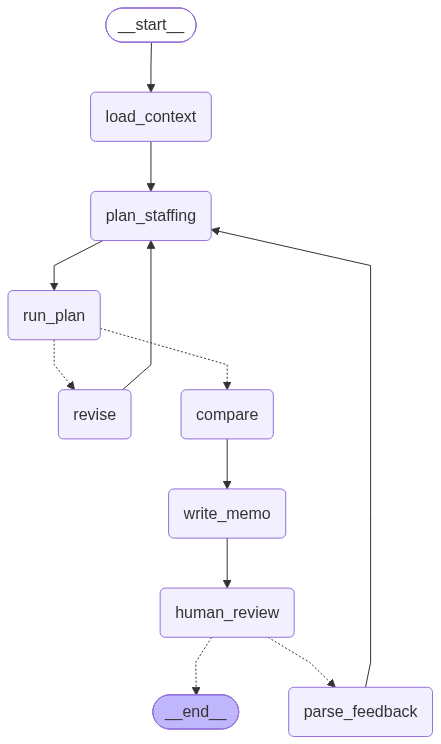

In [30]:
# ==========================================================
# 7. Build, wire, and visualize the graph
# ==========================================================
from IPython.display import Image, Markdown, display
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

# Initialize the Graph Builder
builder = StateGraph(StaffingState)

# Add Nodes
builder.add_node("load_context", load_context)      # inputs, baseline, heuristic
builder.add_node("plan_staffing", plan_staffing)    # analysis + candidate plans
builder.add_node("run_plan", run_plan)              # score all candidates
builder.add_node("revise", revise)                  # fix / refine feedback
builder.add_node("compare", compare)                # AI vs heuristic vs baseline
builder.add_node("write_memo", write_memo)          # memo
builder.add_node("human_review", human_review)      # approval
builder.add_node("parse_feedback", parse_feedback)  # feedback -> constraints

# Define Graph Flow
builder.add_edge(START, "load_context")
builder.add_edge("load_context", "plan_staffing")
builder.add_edge("plan_staffing", "run_plan")
builder.add_conditional_edges("run_plan", check_plan)          # → revise or compare
builder.add_edge("revise", "plan_staffing")                     # revise loop
builder.add_edge("compare", "write_memo")
builder.add_edge("write_memo", "human_review")
builder.add_conditional_edges("human_review", review_decision)  # → END or parse_feedback
builder.add_edge("parse_feedback", "plan_staffing")             # feedback loop

# Compile with a checkpointer (needed for interrupt/resume)
graph = builder.compile(checkpointer=MemorySaver())

# Visualize
display(Image(graph.get_graph().draw_mermaid_png()))

In [31]:
# ==========================================================
# 8. Display helpers
# ==========================================================
def show_comparison(cmp):
    """Plan comparison as a table."""
    df = pd.DataFrame(cmp["plans"]).T
    money = ["net_with_carryover", "net_financial_impact", "total_staffing_cost", "expected_revenue_uplift"]
    fmt = {k: "${:,.0f}" for k in money}
    fmt.update({"expiration_rate": "{:.2%}", "average_utilization": "{:.1%}",
                "average_wait_days": "{:.1f}", "advertisers_supported": "{:,.0f}",
                "advertisers_expired": "{:,.0f}"})
    display(df.style.format(fmt, na_rep="–"))


def show_memo(memo):
    n, cmp = memo["narrative"], memo["numbers"]
    text = (f"### {cmp['country']}: {n['headline']}\n\n"
            f"**Final plan:** {cmp['final_plan']} (AI attempts: {cmp['attempts']})\n\n"
            f"**Why this plan:** {n['why_this_plan']}\n\n"
            f"**AI vs heuristic:** {n['ai_vs_heuristic']}\n\n"
            "**Risks**\n" + "".join(f"\n- {r}" for r in n["risks"]) + "\n\n"
            "**Assumptions**\n" + "".join(f"\n- {a}" for a in n["assumptions"]))
    display(Markdown(text))
    show_comparison(cmp)
    levels = pd.Series(cmp["final_levels"], index=MONTHS_2026, name="Productive agents")
    display(levels.to_frame().T)

## 9. Single-Country Run

Each run uses a `thread_id` (the country name) so the checkpointer keeps separate progress per country. The
first `invoke` runs until `human_review` pauses; the memo is returned under `__interrupt__`.

In [32]:
# ==========================================================
# 9. Run Brazil until the human review pause
# ==========================================================
country = "Brazil"
config = {"configurable": {"thread_id": country}}

result = graph.invoke({"country": country}, config)
show_memo(result["__interrupt__"][0].value["memo"])

--- load_context: Brazil ---
--- plan_staffing (attempt 1) ---
--- run_plan (attempt 1) ---
  Aggressive: net with carry-over $43,985,411 | pass
    agents: [189, 121, 123, 90, 95, 93, 73, 79, 100, 124, 127, 129]
  Moderate: net with carry-over $43,771,128 | pass
    agents: [189, 131, 133, 100, 105, 103, 83, 89, 110, 134, 137, 139]
  Conservative: net with carry-over $43,449,703 | pass
    agents: [189, 146, 148, 115, 120, 118, 98, 104, 125, 149, 152, 154]
--- revise (refine) after attempt 1 ---
--- plan_staffing (attempt 2) ---
--- run_plan (attempt 2) ---
  Adjusted Aggressive: net with carry-over $43,942,555 | pass
    agents: [189, 123, 125, 92, 97, 95, 75, 81, 102, 126, 129, 131]
  Moderate Buffer: net with carry-over $43,835,413 | pass
    agents: [189, 128, 130, 97, 102, 100, 80, 86, 107, 131, 134, 136]
  Lean Minimum: net with carry-over $44,049,696 | pass
    agents: [189, 118, 120, 87, 92, 90, 70, 76, 97, 121, 124, 126]
--- revise (refine) after attempt 2 ---
--- plan_staffi

### Brazil: Adopt the AI plan for Brazil to optimize net financial impact with balanced staffing and utilization.

**Final plan:** AI (AI attempts: 3)

**Why this plan:** The AI plan offers a superior net financial impact ($44,959,002.98) compared to Baseline and Heuristic plans, while maintaining the highest average utilization (0.835) and zero advertiser expiration, ensuring efficient resource use without sacrificing service quality.

**AI vs heuristic:** Compared to the Heuristic plan, the AI plan achieves slightly lower net financial impact ($44,959,002.98 vs. $45,091,299.65) but significantly improves average utilization (0.835 vs. 0.72) with a modest increase in staffing cost, indicating a more efficient allocation of resources.

**Risks**

- Demand spikes could exceed the no-buffer staffing, risking advertiser expiration despite zero expiration in forecasts.
- Aggressive cuts with no rehires may lead to insufficient capacity if unexpected workload increases occur.
- Persistent idle capacity in some months could still incur unnecessary costs.
- Potential severance and ramp-up costs if future rehiring becomes necessary due to under-staffing.

**Assumptions**

- Advertiser demand remains stable with zero expiration rate as forecasted.
- No rehires will be necessary after initial cuts, avoiding churn costs.
- The net financial impact calculations include 3 months of 2027 salary at December headcount as per scoring note.
- Average wait days remain zero, indicating no service delays under the plan.

,net_with_carryover,net_financial_impact,total_staffing_cost,expected_revenue_uplift,advertisers_supported,advertisers_expired,expiration_rate,average_wait_days,average_utilization
Baseline,"$42,933,560","$44,254,197","$5,282,550","$49,536,747","5,651",0,0.00%,0.0,44.8%
Heuristic,"$44,147,987","$45,091,300","$4,445,448","$49,536,747","5,651",0,0.00%,0.0,72.0%
AI,"$44,092,553","$44,959,003","$4,577,744","$49,536,747","5,651",0,0.00%,0.0,83.5%


,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11,2026-12
Productive agents,189,116,118,85,90,88,68,74,95,119,122,124


In [33]:
# ==========================================================
# 10. Manager feedback
# ----------------------------------------------------------
# parse_feedback turns this into PlanConstraints, the LLM re-plans,
# run_plan enforces the new rules, and the graph pauses again.
# ==========================================================
result = graph.invoke(Command(resume="Don't give anyone notice before June, and never go below 110 agents"),
                      config)
show_memo(result["__interrupt__"][0].value["memo"])

--- human_review (paused) ---
--- parse_feedback ---
New constraints: {'min_agents': 110, 'no_terminations_before': '2026-06'}
--- plan_staffing (attempt 1) ---
--- run_plan (attempt 1) ---
  Aggressive: net with carry-over $43,228,898 | pass
    agents: [189, 189, 189, 189, 189, 189, 110, 110, 120, 130, 135, 140]
  Moderate: net with carry-over n/a | fail: 2026-07: 82 agents is below the minimum of 110.
    agents: [189, 189, 189, 189, 189, 189, 82, 89, 114, 143, 147, 149]
  Conservative: net with carry-over $42,837,598 | fail: Net impact with carry-over $42,837,598 is worse than keeping current staffing ($42,933,560).
    agents: [189, 189, 189, 189, 189, 189, 150, 150, 160, 170, 175, 180]
--- revise (refine) after attempt 1 ---
--- plan_staffing (attempt 2) ---
--- run_plan (attempt 2) ---
  Aggressive+: net with carry-over $43,310,419 | pass
    agents: [189, 189, 189, 189, 189, 189, 110, 110, 120, 125, 130, 135]
  Moderate: net with carry-over $43,305,760 | pass
    agents: [189, 

### Brazil: Adopt the AI plan for Brazil to optimize staffing costs while maintaining service levels and minimizing churn.

**Final plan:** AI (AI attempts: 3)

**Why this plan:** The AI plan balances cost savings and operational efficiency better than the Baseline and Heuristic plans by reducing idle staffing costs and smoothing ramp-up to avoid costly churn, resulting in a higher net financial impact despite slightly higher staffing costs than the Heuristic plan.

**AI vs heuristic:** Compared to the Heuristic plan, the AI plan achieves a slightly lower total staffing cost but a marginally lower net financial impact; however, it improves average utilization significantly (0.59 vs 0.55) and implements a more gradual ramp-up strategy that reduces churn and idle costs, making it operationally superior.

**Risks**

- Demand exceeds forecast leading to understaffing and increased wait times.
- Overly aggressive cuts causing the need for costly rehiring and ramp-up.
- Potential delays in ramp-up causing temporary service degradation.
- Unforeseen changes in advertiser behavior affecting support needs.

**Assumptions**

- No terminations before June 2026 as per constraints.
- Minimum staffing level of 110 agents maintained.
- Advertisers supported remain constant at 5651 with zero expiration rate.
- Nets include 3 months of 2027 salary at December headcount as per scoring note.

,net_with_carryover,net_financial_impact,total_staffing_cost,expected_revenue_uplift,advertisers_supported,advertisers_expired,expiration_rate,average_wait_days,average_utilization
Baseline,"$42,933,560","$44,254,197","$5,282,550","$49,536,747","5,651",0,0.00%,0.0,44.8%
Heuristic,"$43,461,815","$44,405,127","$5,131,620","$49,536,747","5,651",0,0.00%,0.0,54.6%
AI,"$43,403,585","$44,311,960","$5,224,787","$49,536,747","5,651",0,0.00%,0.0,59.0%


,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11,2026-12
Productive agents,189,189,189,189,189,189,110,110,115,120,125,130


In [34]:
# ==========================================================
# 11. Approve and show the final plan
# ==========================================================
result = graph.invoke(Command(resume="approve"), config)

final_plan = pd.DataFrame(result["comparison"]["final_decisions"])
final_plan["Agents"] = result["comparison"]["final_levels"]
if result["comparison"]["final_plan"] == "AI":
    final_plan["Reason"] = final_plan["Month"].map(result["best"]["reasons"]).fillna("January fixed")
display(final_plan)
display(pd.DataFrame(result["comparison"]["attempt_log"]))

--- human_review (paused) ---


,Country,Month,Hires,Terminations,Agents,Reason
0,Brazil,2026-01,0,0,189,January fixed
1,Brazil,2026-02,0,0,189,No terminations allowed before June; keep curr...
2,Brazil,2026-03,0,0,189,No terminations allowed before June; keep curr...
3,Brazil,2026-04,0,0,189,No terminations allowed before June; keep curr...
4,Brazil,2026-05,0,0,189,No terminations allowed before June; keep curr...
5,Brazil,2026-06,0,79,189,No terminations allowed before June; keep curr...
6,Brazil,2026-07,0,0,110,"Cut to minimum allowed; lowest busy agents, ma..."
7,Brazil,2026-08,5,0,110,Demand still low; keep at minimum.
8,Brazil,2026-09,5,0,115,Slight ramp-up for September busy agents (95);...
9,Brazil,2026-10,5,0,120,October busy agents (119); add 5 more agents.


,attempt,candidate,passed,net_with_carryover,first_issue
0,1,Aggressive,True,4.322890e+07,
1,1,Moderate,False,NaN,2026-07: 82 agents is below the minimum of 110.
2,1,Conservative,False,4.283760e+07,"Net impact with carry-over $42,837,598 is wors..."
3,2,Aggressive+,True,4.331042e+07,
4,2,Moderate,True,4.330576e+07,
5,2,Conservative,True,4.315902e+07,
6,3,Aggressive+ Adjusted,True,4.340359e+07,
7,3,Moderate Buffer,True,4.330576e+07,
8,3,Conservative Buffer,True,4.315902e+07,


## 12. All Countries (Just 4 for now for prototyping purposes)

Runs the graph once per country with automatic approval and collects the results. All nets in the summary include
the 2027 carry-over; `Final_Net_2026` is Tool 3's 2026-only figure for the chosen plan.

In [35]:
# ==========================================================
# 12. All countries (auto-approve) and summary
# ==========================================================
all_decisions, summary_rows = [], []

#for country in df_exist_staff["Country"]:
for country in ["USA", "UK", "India", "Brazil"]:
    config = {"configurable": {"thread_id": f"all-{country}"}}
    graph.invoke({"country": country}, config)                 # runs to human_review
    result = graph.invoke(Command(resume="approve"), config)   # auto-approve

    cmp = result["comparison"]
    all_decisions.append(pd.DataFrame(cmp["final_decisions"]))
    p = cmp["plans"]
    final_key = cmp["final_plan"].split(" ")[0]
    summary_rows.append({
        "Country": country,
        "Final_Plan": cmp["final_plan"],
        "AI_Attempts": cmp["attempts"],
        "Baseline_Net": p["Baseline"]["net_with_carryover"],
        "Heuristic_Net": p.get("Heuristic", {}).get("net_with_carryover"),
        "AI_Net": p.get("AI", {}).get("net_with_carryover"),
        "Final_Net": p[final_key]["net_with_carryover"],
        "Final_Net_2026": p[final_key]["net_financial_impact"],
        "AI_Expiration": p.get("AI", {}).get("expiration_rate"),
    })

staffing_decisions_2026 = pd.concat(all_decisions, ignore_index=True)
summary_2026 = pd.DataFrame(summary_rows)
summary_2026["AI_minus_Heuristic"] = summary_2026["AI_Net"] - summary_2026["Heuristic_Net"]
summary_2026["Final_minus_Baseline"] = summary_2026["Final_Net"] - summary_2026["Baseline_Net"]
money = ["Baseline_Net", "Heuristic_Net", "AI_Net", "Final_Net", "Final_Net_2026",
         "AI_minus_Heuristic", "Final_minus_Baseline"]
display(summary_2026.style.format({c: "${:,.0f}" for c in money} | {"AI_Expiration": "{:.2%}"},
                                  na_rep="–"))

print(f"AI plan used in {(summary_2026['Final_Plan'] == 'AI').sum()} of {len(summary_2026)} countries")
print(f"AI beat or matched the heuristic in "
      f"{(summary_2026['AI_minus_Heuristic'] >= 0).sum()} of {summary_2026['AI_Net'].notna().sum()} countries")
print(f"Total net gain over baseline: ${summary_2026['Final_minus_Baseline'].sum():,.0f}")

--- load_context: USA ---
--- plan_staffing (attempt 1) ---
--- run_plan (attempt 1) ---
  Aggressive: net with carry-over $111,048,898 | pass
    agents: [652, 280, 280, 220, 195, 190, 150, 185, 235, 280, 285, 275]
  Moderate: net with carry-over $108,581,256 | pass
    agents: [652, 310, 315, 245, 215, 210, 165, 205, 260, 315, 320, 305]
  Conservative: net with carry-over $103,749,601 | pass
    agents: [652, 375, 385, 300, 265, 260, 200, 250, 320, 385, 390, 375]
--- revise (refine) after attempt 1 ---
--- plan_staffing (attempt 2) ---
--- run_plan (attempt 2) ---
  Smoothed Aggressive: net with carry-over $112,285,957 | pass
    agents: [652, 280, 280, 220, 200, 190, 170, 170, 220, 270, 275, 265]
  Moderate Phased Reduction: net with carry-over $111,819,631 | pass
    agents: [652, 320, 300, 240, 210, 190, 180, 190, 230, 270, 275, 265]
  Conservative Buffer: net with carry-over $109,863,653 | pass
    agents: [652, 350, 340, 300, 270, 250, 240, 250, 270, 300, 310, 300]
--- revise (r

,Country,Final_Plan,AI_Attempts,Baseline_Net,Heuristic_Net,AI_Net,Final_Net,Final_Net_2026,AI_Expiration,AI_minus_Heuristic,Final_minus_Baseline
0,USA,AI,3,"$90,741,696","$111,409,005","$113,412,912","$113,412,912","$118,561,928",0.00%,"$2,003,906","$22,671,216"
1,UK,AI,3,"$13,246,944","$31,135,922","$31,336,496","$31,336,496","$33,015,121",0.00%,"$200,574","$18,089,552"
2,India,AI,3,"$85,036,321","$86,044,346","$86,207,644","$86,207,644","$87,301,789",0.00%,"$163,298","$1,171,323"
3,Brazil,AI,3,"$42,933,560","$44,147,987","$44,353,885","$44,353,885","$45,220,335",0.00%,"$205,898","$1,420,326"


AI plan used in 4 of 4 countries
AI beat or matched the heuristic in 4 of 4 countries
Total net gain over baseline: $43,352,417


## 13. Sensitivity Analysis

Every plan above was scored on one simulated 2026: the forecast volume and one random draw of advertisers.
This section asks how each plan holds up when sign-ups differ from the forecast. Plans are **locked in**:
headcount is set a month ahead, so demand changes but the staffing path does not.

Three plans are tested per country: **Baseline** (keep current staffing), **Heuristic** and **AI**, as chosen in
section 12 (read back from each country's checkpointed run). No LLM calls are made.

| Test | What changes | Question it answers |
|---|---|---|
| Volume scenarios | Sign-ups -20%, -10%, 0%, +10%, +20% in every month | How do cost, net and expirations move with demand? |
| Random draws | Same forecast volume, different random sign-up days and budgets | Does the plan hold up beyond the one draw it was tuned to? |
| Headroom | Volume raised in 2% steps up to +40% | How much extra demand can the plan absorb before more than 1% of advertisers expire? |

A plan whose cut would strand advertisers already in support is rejected by the simulator. Here that is recorded
as **infeasible** for that scenario (the cut could not be made at that volume) instead of stopping the run.

Countries tested are the ones run in section 12. Scores use `evaluate_plan()` (Tool 3) unchanged, and nets include
the 2027 carry-over, as in the rest of Part 2.

In [ ]:
# ==========================================================
# 13a. Sensitivity settings and helpers (no LLM)
# ----------------------------------------------------------
# Defines:
#   - scale_advertisers() : raise or lower sign-up volume, keeping the base draw
#   - score_under()       : Tool 2 -> fast simulator -> Tool 3 on a given set of advertisers
#   - plans_for()         : Baseline / Heuristic / AI headcount paths from section 12's runs
#   - headroom()          : largest volume increase a plan absorbs within the expiration limit
# ==========================================================
SENS_VOLUMES = [-0.20, -0.10, 0.00, 0.10, 0.20]   # sign-up volume changes vs the forecast
SENS_SEEDS = list(range(1, 21))                    # random draws at forecast volume
SENS_BASE_SEED = 42                                # seed used to scale the base draw up or down
HEADROOM_STEP = 0.02                               # headroom search step (+2% demand)
HEADROOM_MAX = 0.40                                # stop searching at +40% demand
SENS_COUNTRIES = summary_2026["Country"].tolist()  # countries run in section 12
PLAN_NAMES = ["Baseline", "Heuristic", "AI"]


def scale_advertisers(base, change, seed=SENS_BASE_SEED):
    """Change sign-up volume by `change` (e.g. +0.10) within each country and month, keeping the base draw.
    Decreases drop a random share of advertisers; increases add re-sampled copies from the same country
    and month (same sign-up days and budgets)."""
    if change == 0:
        return base.reset_index(drop=True)
    parts = []
    month = base["Sign_Up_Date"].dt.month
    for g, ((country, m), grp) in enumerate(base.groupby([base["Country"], month])):
        rng = np.random.default_rng(seed + g)          # one stream per country-month
        n = int(round(len(grp) * (1 + change)))
        if n <= len(grp):
            parts.append(grp.loc[rng.permutation(grp.index)[:n]])
        else:
            extra = grp.loc[grp.index[rng.integers(0, len(grp), size=n - len(grp))]].copy()
            extra["Advertiser_ID"] = [f"{a}_S{i}" for i, a in enumerate(extra["Advertiser_ID"])]
            parts += [grp, extra]
    out = pd.concat(parts)
    return out.sort_values(["Country", "Sign_Up_Date", "Advertiser_ID"]).reset_index(drop=True)


def score_under(country, start_agents, levels, advertisers):
    """Score a fixed headcount path against a given set of advertisers.
    A cut that strands supported advertisers is returned as infeasible rather than raised."""
    dec = pd.DataFrame(levels_to_decisions(country, levels))
    dec["Month"] = pd.PeriodIndex(dec["Month"], freq="M")
    plan = build_staffing_schedule(initial_agents=start_agents, decisions=dec)
    try:
        adv, daily = simulate_country_fast(advertisers, country, plan, "2026-01-01", "2026-12-31")
    except ValueError as e:
        return {"feasible": False, "issue": str(e)}
    m = evaluate_plan(adv, daily, plan)
    carryover = CARRYOVER_MONTHS * float(plan["Monthly_Salary"].iloc[-1]) * float(plan["Paid_Agents"].iloc[-1])
    return {"feasible": True, "issue": "",
            "advertisers": len(adv),
            "advertisers_expired": int(m["advertisers_expired"]),
            "expiration_rate": float(m["expiration_rate"]),
            "average_wait_days": float(m["average_wait_days"]),
            "p90_wait_days": float(m["p90_wait_days"]),
            "peak_waiting": int(daily["waiting"].max()),
            "average_utilization": float(m["average_utilization"]),
            "total_staffing_cost": float(m["total_staffing_cost"]),
            "expected_revenue_uplift": float(m["expected_revenue_uplift"]),
            "net_financial_impact": float(m["net_financial_impact"]),
            "net_with_carryover": float(m["net_financial_impact"]) - carryover}


def plans_for(country):
    """Headcount paths from the country's section 12 run (thread 'all-<country>')."""
    state = graph.get_state({"configurable": {"thread_id": f"all-{country}"}}).values
    start = state["context"]["start_agents"]
    plans = {"Baseline": [start] * 12, "Heuristic": state["heuristic"]["levels"]}
    if state.get("best"):
        plans["AI"] = state["best"]["levels"]
    return start, plans, state["comparison"]["final_plan"]


def headroom(country, start_agents, levels, base):
    """Largest volume increase on the grid with <= MAX_EXPIRATION_RATE expired and no stranded cuts.
    Returns None if the plan already fails at forecast volume."""
    ok = None
    for change in np.round(np.arange(0, HEADROOM_MAX + 1e-9, HEADROOM_STEP), 4):
        r = score_under(country, start_agents, levels, scale_advertisers(base, change))
        if not r["feasible"] or r["expiration_rate"] > MAX_EXPIRATION_RATE:
            return ok
        ok = float(change)
    return ok                                       # absorbed every step up to HEADROOM_MAX


sens_plans = {c: plans_for(c) for c in SENS_COUNTRIES}
for c, (start, plans, final) in sens_plans.items():
    print(f"{c}: final plan {final} | plans tested: {', '.join(plans)}")

### Volume scenarios

Each country's forecast draw is scaled up or down in every month, and the three locked-in plans are re-scored
on the same scaled advertisers.

In [ ]:
# ==========================================================
# 13b. Volume scenarios
# ==========================================================
rows = []
for c, (start, plans, final) in sens_plans.items():
    base = ad_forecast_2026[ad_forecast_2026["Country"] == c]
    for change in SENS_VOLUMES:
        advertisers = scale_advertisers(base, change)
        for name, levels in plans.items():
            rows.append({"Country": c, "Plan": name, "Volume": change, "Final": name == final.split(" ")[0],
                         **score_under(c, start, levels, advertisers)})
    print(f"{c}: done")

sens_volume = pd.DataFrame(rows)

# Net with carry-over and expiration rate by plan and volume (blank = infeasible at that volume)
vol_labels = {v: f"{v:+.0%}" for v in SENS_VOLUMES}
net_table = sens_volume.pivot_table(index=["Country", "Plan"], columns="Volume", values="net_with_carryover")
exp_table = sens_volume.pivot_table(index=["Country", "Plan"], columns="Volume", values="expiration_rate")
print("Net impact with carry-over")
display(net_table.rename(columns=vol_labels).style.format("${:,.0f}", na_rep="infeasible"))
print("Expiration rate")
display(exp_table.rename(columns=vol_labels).style.format("{:.2%}", na_rep="infeasible"))

infeasible = sens_volume[~sens_volume["feasible"]]
if len(infeasible):
    print("Infeasible scenarios (a planned cut would strand supported advertisers):")
    display(infeasible[["Country", "Plan", "Volume", "issue"]])

### Random draws at forecast volume

The 2026 advertisers are regenerated with different seeds (same monthly forecast counts, different sign-up days
and budgets). The spread shows how much of each plan's result depends on the single draw it was planned on.

In [ ]:
# ==========================================================
# 13c. Random draws at forecast volume
# ==========================================================
fc_sens = forecast_2026[forecast_2026["Country"].isin(SENS_COUNTRIES)]
rows = []
for seed in SENS_SEEDS:
    draw = create_2026_forecast_advertisers(fc_sens, historical_advertisers=eligible_ad, random_seed=seed)
    for c, (start, plans, final) in sens_plans.items():
        for name, levels in plans.items():
            rows.append({"Country": c, "Plan": name, "Seed": seed, **score_under(c, start, levels, draw)})
    print(f"seed {seed}: done")

sens_seeds = pd.DataFrame(rows)

def p10(s): return s.quantile(0.10)
def p90(s): return s.quantile(0.90)

seed_summary = (sens_seeds.groupby(["Country", "Plan"])
                .agg(Draws=("Seed", "count"),
                     Infeasible=("feasible", lambda s: int((~s).sum())),
                     Net_P10=("net_with_carryover", p10),
                     Net_Median=("net_with_carryover", "median"),
                     Net_P90=("net_with_carryover", p90),
                     Expiration_Median=("expiration_rate", "median"),
                     Expiration_P90=("expiration_rate", p90),
                     Draws_Over_Limit=("expiration_rate", lambda s: int((s > MAX_EXPIRATION_RATE).sum()))))
money = ["Net_P10", "Net_Median", "Net_P90"]
display(seed_summary.style.format({c: "${:,.0f}" for c in money}
                                  | {"Expiration_Median": "{:.2%}", "Expiration_P90": "{:.2%}"}, na_rep="–"))

### Headroom

Volume is raised in 2% steps from the forecast. A plan's headroom is the largest increase it absorbs with no more
than 1% of advertisers expiring and no stranded cuts. "Fails at forecast" means it is already over the limit at
0%.

In [ ]:
# ==========================================================
# 13d. Headroom: extra demand each plan absorbs
# ==========================================================
rows = []
for c, (start, plans, final) in sens_plans.items():
    base = ad_forecast_2026[ad_forecast_2026["Country"] == c]
    row = {"Country": c, "Final_Plan": final}
    for name, levels in plans.items():
        row[f"Headroom_{name}"] = headroom(c, start, levels, base)
    rows.append(row)
    print(f"{c}: done")

sens_headroom = pd.DataFrame(rows)

def fmt_headroom(v):
    if v is None or pd.isna(v):
        return "fails at forecast"
    return f">= +{HEADROOM_MAX:.0%}" if v >= HEADROOM_MAX else f"+{v:.0%}"

display(sens_headroom.style.format({f"Headroom_{p}": fmt_headroom for p in PLAN_NAMES}, na_rep="–"))

### Sensitivity summary

One row per country: headroom for each plan, AI vs heuristic net at low, forecast and high volume, and the AI
plan's spread across random draws. The charts show net impact and expiration rate against volume for each plan.

In [ ]:
# ==========================================================
# 13e. Summary table and charts
# ==========================================================
import matplotlib.pyplot as plt

lo, hi = min(SENS_VOLUMES), max(SENS_VOLUMES)

def vol_value(c, plan, change, col="net_with_carryover"):
    r = sens_volume[(sens_volume["Country"] == c) & (sens_volume["Plan"] == plan)
                    & (sens_volume["Volume"] == change)]
    return r[col].iloc[0] if len(r) else np.nan

rows = []
for c, (start, plans, final) in sens_plans.items():
    h = sens_headroom.set_index("Country").loc[c]
    row = {"Country": c, "Final_Plan": final,
           "Headroom_Heuristic": h.get("Headroom_Heuristic"), "Headroom_AI": h.get("Headroom_AI")}
    for change in (lo, 0.0, hi):
        row[f"AI_minus_Heuristic_{change:+.0%}"] = vol_value(c, "AI", change) - vol_value(c, "Heuristic", change)
    row[f"AI_Expiration_{hi:+.0%}"] = vol_value(c, "AI", hi, "expiration_rate")
    if "AI" in plans:
        s = seed_summary.loc[(c, "AI")]
        row["AI_Net_P10_draws"], row["AI_Net_P90_draws"] = s["Net_P10"], s["Net_P90"]
    rows.append(row)

sensitivity_summary_2026 = pd.DataFrame(rows)
money = [col for col in sensitivity_summary_2026.columns if col.startswith(("AI_minus", "AI_Net"))]
display(sensitivity_summary_2026.style.format(
    {col: "${:,.0f}" for col in money}
    | {"Headroom_Heuristic": fmt_headroom, "Headroom_AI": fmt_headroom,
       f"AI_Expiration_{hi:+.0%}": "{:.2%}"}, na_rep="–"))

# Charts: net impact and expiration rate vs volume, one row per country
fig, axes = plt.subplots(len(SENS_COUNTRIES), 2, figsize=(11, 3.2 * len(SENS_COUNTRIES)), squeeze=False)
for i, c in enumerate(SENS_COUNTRIES):
    for name in sens_plans[c][1]:
        d = sens_volume[(sens_volume["Country"] == c) & (sens_volume["Plan"] == name)].sort_values("Volume")
        axes[i, 0].plot(d["Volume"] * 100, d["net_with_carryover"] / 1e6, marker="o", label=name)
        axes[i, 1].plot(d["Volume"] * 100, d["expiration_rate"] * 100, marker="o", label=name)
    axes[i, 0].set_title(f"{c}: net impact with carry-over ($M)")
    axes[i, 1].set_title(f"{c}: advertisers expired (%)")
    axes[i, 1].axhline(MAX_EXPIRATION_RATE * 100, color="grey", linestyle="--", linewidth=1)
    for ax in axes[i]:
        ax.set_xlabel("Sign-up volume vs forecast (%)")
        ax.grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## Summary

- **The LLM decides** monthly headcount. It writes an analysis first, proposes three candidate plans per attempt, and uses a larger planning model.
- **Python verifies** every candidate: conversion to hires and notices, validation, then Tools 1–3 (with a faster, equivalent simulator).
- **Feedback is specific.** Failed attempts get month-by-month idle costs and a cost breakdown; passing plans get up to two refine rounds, and the best plan is kept.
- **Scoring includes carry-over,** so late-year cuts are judged on their full savings rather than only the part that lands in 2026.
- **The heuristic** is the fallback and the benchmark. It is never shown to the LLM, so the AI-vs-heuristic comparison is a fair test.
- **Checkpointer + `interrupt`** turn the graph into a human-in-the-loop approval workflow for actual use in production.